# Closing filters: opening versus closing Brier history

Same plot families as trend_smoothing_open.ipynb, for **close1 and close2 returns from the opening inference model**. Validation uses the train-only fit; test uses its train+validation refit. No probability models or strategy parameters are refitted here.

Sweep EWMA and simple rolling trend smoothing over 5/10 events, with +/-0.02 and +/-0.03 bands. Detailed diagnostics use **EWMA-5, +/-0.02**. Advantage remains a 100-fight average sampled at event end; slope uses the last 5 smoothed event points, normalized by the original training-period standard deviation, and shifted before the event. Mean groups compare prior advantage with the prior five-calendar-year event-end mean.

**Opening history** transfers opening trend selection and opening stake multipliers onto closing returns. **Closing history** uses that market's Brier history, trend selection, and scalers fitted on its own prior returns. These comparisons change both gate and scalers. An additional four-way comparison crosses gate and scaler sources to distinguish their effects. Multipliers are computed for every event, including events rejected by their own gate, using only earlier eligible events for Brier regression; this allows a valid crossed comparison.

Volatility uses the last 10 above-mean non-flat events as its fixed target; the denominator uses the last 10 current-mean-group events including flats. Prior-Brier is reduction-only (minimum 20 earlier non-flat observations, ridge penalty 10, nonnegative coefficient). All scalers use original historical returns. Flat events are skipped in performance unless explicitly labeled raw. Boxplots and mean-group bars include flats. Histories carry into test, but separate-period bankroll plots reset to 500.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/ufc_betting').is_dir())
if str(ROOT/'src') not in sys.path: sys.path.insert(0,str(ROOT/'src'))
from ufc_betting.config import settings
WINDOW_FIGHTS=100
FLAT_BAND=.02
SMOOTH_SPAN=5
SMOOTH_METHOD="EWMA"
SLOPE_EVENTS=5
VOL_EVENTS=10
BRIER_MIN_EVENTS=20
BRIER_RIDGE=10.
PREDICTIONS=settings.data_dir/'model_comparisons/lr_open_close/report_predictions'
BACKTESTS=settings.data_dir/'backtest_results/model_comparisons/inference_market_models'
KEYS=['date','fighter_red','fighter_blue']

def score_fights(frame,market):
    frame=frame.copy();frame['date']=pd.to_datetime(frame.date).dt.normalize()
    p=pd.to_numeric(frame.proba_red,errors='coerce')
    r=pd.to_numeric(frame[f'dec_{market}_red'],errors='coerce');b=pd.to_numeric(frame[f'dec_{market}_blue'],errors='coerce')
    valid=frame.winner.isin([0,1])&p.between(0,1)&np.isfinite(r)&np.isfinite(b)&r.gt(1)&b.gt(1)
    q=(1/r)/(1/r+1/b)
    frame=frame.loc[valid].copy()
    frame['vegas_actual']=(q.loc[valid]-frame.winner)**2
    frame['vegas_expected']=q.loc[valid]*(1-q.loc[valid])
    frame['model_brier']=(p.loc[valid]-frame.winner)**2
    frame['excess']=frame.vegas_actual-frame.vegas_expected
    frame['advantage']=frame.vegas_actual-frame.model_brier
    return frame.sort_values('date',kind='stable').reset_index(drop=True)

def metrics(returns):
    r=np.asarray(returns,float)/100
    assert np.isfinite(r).all() and (r>-1).all()
    wealth=np.r_[1.,np.cumprod(1+r)]
    return dict(events=len(r),geometric_growth_pct=100*np.expm1(np.log1p(r).mean()),
        average_return_pct=100*r.mean(),volatility_pp=100*r.std(ddof=1),
        worst_event_pct=100*r.min(),max_drawdown_pct=-100*(wealth/np.maximum.accumulate(wealth)-1).min(),
        final_wealth=wealth[-1])

# Opening notebook's event gate is independent of the closing-trend diagnostics.
OPENING_FLAT_BAND = .03

def opening_event_filter():
    rows=[]
    train_end=pd.to_datetime(pd.read_csv(PREDICTIONS/'train/open/inference/train_with_open.csv').date).max()
    for label,fit,split,prefix in [('Validation','train','val','train_val'),('Test','trainval','test','trainval_test')]:
        root=PREDICTIONS/fit/'open/inference'
        warm=score_fights(pd.read_csv(root/'train_with_open.csv'),'open')
        pred=pd.read_csv(root/f'{split}_with_open.csv',parse_dates=['date'])
        saved=pd.read_csv(BACKTESTS/f'{prefix}_open_with_open_inference_no_decay_moneylines.csv',parse_dates=['date'])
        current=score_fights(saved[KEYS].merge(pred,on=KEYS,validate='one_to_one',sort=False),'open')
        history=pd.concat([warm,current],ignore_index=True).sort_values('date',kind='stable')
        history['rolling']=history.advantage.rolling(WINDOW_FIGHTS,min_periods=WINDOW_FIGHTS).mean()
        ends=history.groupby('date')['rolling'].last().dropna()
        smoothed=(ends.ewm(span=SMOOTH_SPAN,adjust=False).mean() if SMOOTH_METHOD=='EWMA' else ends.rolling(SMOOTH_SPAN,min_periods=SMOOTH_SPAN).mean())
        t=np.arange(SLOPE_EVENTS,dtype=float);t-=t.mean()
        slopes=smoothed.rolling(SLOPE_EVENTS).apply(lambda v:np.dot(t,v)/np.dot(t,t),raw=True)
        sd=smoothed.loc[smoothed.index<=train_end].std(ddof=1)
        dates=pd.DatetimeIndex(sorted(saved.date.unique()))
        part=pd.DataFrame({'opening_prior_slope':slopes.shift(1).reindex(dates)/sd,
            'opening_source_date':pd.Series(ends.index,index=ends.index).shift(1).reindex(dates)})
        assert part.notna().all().all() and (part.opening_source_date<part.index).all()
        part['opening_keep']=part.opening_prior_slope.abs().gt(OPENING_FLAT_BAND)
        rows.append(part)
    result=pd.concat(rows).sort_index()
    assert result.index.is_unique and result.opening_keep.any()
    return result

OPENING_EVENT_FILTER=opening_event_filter()

def analyze_closing(market):
    band=OPENING_FLAT_BAND if market=='open' else FLAT_BAND
    histories={};parts=[]
    train_end=pd.to_datetime(pd.read_csv(PREDICTIONS/'train/open/inference/train_with_open.csv').date).max()
    for label,fit,split,prefix in [('Validation','train','val','train_val'),('Test','trainval','test','trainval_test')]:
        root=PREDICTIONS/fit/'open/inference'
        pred=pd.read_csv(root/f'{split}_with_{market}.csv',parse_dates=['date'])
        warm=score_fights(pd.read_csv(root/f'train_with_{market}.csv'),market)
        saved=pd.read_csv(BACKTESTS/f'{prefix}_open_with_{market}_inference_{"no_decay" if market=="open" else "decay"}_moneylines.csv',parse_dates=['date'])
        assert pred.probability_model.eq('inference').all()
        saved['date']=saved.date.dt.normalize();pred['date']=pred.date.dt.normalize()
        check=saved.merge(pred[KEYS+['proba_red']],on=KEYS,how='outer',validate='one_to_one',indicator=True,suffixes=('','_reference'))
        assert check['_merge'].eq('both').all()
        saved_p=check.proba_red if 'proba_red' in saved else check.choice_proba.where(check.pred_winner.eq(1),1-check.choice_proba)
        reference=check.proba_red_reference if 'proba_red' in saved else check.proba_red
        np.testing.assert_allclose(saved_p,reference,atol=1e-10)
        current=score_fights(saved[KEYS].merge(pred,on=KEYS,validate='one_to_one',sort=False),market)
        assert warm.date.max()<current.date.min()
        history=pd.concat([warm,current],ignore_index=True).sort_values('date',kind='stable').reset_index(drop=True)
        for col in ['vegas_actual','vegas_expected','excess','advantage']:
            history['rolling_'+col]=history[col].rolling(WINDOW_FIGHTS,min_periods=WINDOW_FIGHTS).mean()
        histories[label]=history
        endpoints=history.groupby('date').rolling_advantage.last().dropna()
        event_brier=history.groupby('date').vegas_actual.mean()
        smooth=(endpoints.ewm(span=SMOOTH_SPAN,adjust=False).mean() if SMOOTH_METHOD=='EWMA' else endpoints.rolling(SMOOTH_SPAN,min_periods=SMOOTH_SPAN).mean())
        t=np.arange(SLOPE_EVENTS,dtype=float);t-=t.mean()
        slope=smooth.rolling(SLOPE_EVENTS).apply(lambda v:np.dot(t,v)/np.dot(t,t),raw=True)
        sd=smooth.loc[smooth.index<=train_end].std(ddof=1);assert sd>0
        cols=['bankroll_postevent','event_payout_money_line','parlay_net','event_total_fstar']
        assert saved.groupby('date')[cols].nunique(dropna=False).le(1).all().all()
        event=saved.groupby('date')[cols].first().sort_index()
        profit=event.event_payout_money_line+event.parlay_net
        start=event.bankroll_postevent-profit
        assert start.gt(0).all()
        np.testing.assert_allclose(start.iloc[1:],event.bankroll_postevent.iloc[:-1],rtol=1e-8,atol=1e-8)
        part=pd.DataFrame(index=event.index)
        part['return_pct']=100*profit/start
        part['stake_fraction']=event.event_total_fstar
        assert part.stake_fraction.between(0,1+1e-10).all()
        part['prior_advantage']=endpoints.shift(1).reindex(part.index)
        part['prior_brier']=event_brier.shift(1).reindex(part.index)
        part['slope']=slope.shift(1).reindex(part.index)/sd
        part['source_date']=pd.Series(endpoints.index,index=endpoints.index).shift(1).reindex(part.index)
        part['five_year_mean']=[endpoints.loc[(endpoints.index>=date-pd.DateOffset(years=5))&(endpoints.index<date)].mean() for date in part.index]
        part['regime']=np.where(part.prior_advantage>part.five_year_mean,'Above mean','At/below mean')
        part['trend']=np.select([part.slope>band,part.slope < -band],['Uptrend','Downtrend'],default='Flat')
        part['split']=label
        assert part.notna().all().all() and (part.source_date<part.index).all()
        parts.append(part)
    all_events=pd.concat(parts).sort_index()
    assert all_events.index.is_unique
    all_events['opening_keep']=all_events.trend.ne('Flat')
    active=all_events.loc[all_events.opening_keep].copy()
    decisions=[]
    for date,row in all_events.iterrows():
        past=all_events.loc[all_events.index<date]
        target=past.loc[past.regime.eq('Above mean') & past.trend.ne('Flat')].tail(VOL_EVENTS)
        own=past.loc[past.regime.eq(row.regime)].tail(VOL_EVENTS)
        vol=1.
        if len(target)==VOL_EVENTS and len(own)==VOL_EVENTS:
            denom=own.return_pct.std(ddof=1)
            vol=min(1.,target.return_pct.std(ddof=1)/denom) if denom>1e-12 else 1.
        training=active.loc[active.index<date];brier=1.;prediction=baseline=np.nan
        if len(training)>=BRIER_MIN_EVENTS:
            x=training.prior_brier.to_numpy();y=training.return_pct.to_numpy()
            baseline=y.mean();prediction=baseline
            if x.std()>1e-12:
                z=(x-x.mean())/x.std()
                coef=max(0.,np.dot(z,y-baseline)/(np.dot(z,z)+BRIER_RIDGE))
                prediction=baseline+coef*(row.prior_brier-x.mean())/x.std()
            brier=float(np.clip(prediction/baseline,0,1)) if baseline>1e-12 else float(prediction>0)
        decisions.append(dict(date=date,vol_multiplier=vol,brier_multiplier=brier,combined_multiplier=vol*brier,
            predicted_return_pct=prediction,baseline_return_pct=baseline))
    all_scalers=pd.DataFrame(decisions).set_index('date')
    active=active.join(all_scalers)
    local_scalers=active[['vol_multiplier','brier_multiplier','combined_multiplier']].copy()
    for variant,factor in [('Volatility only','vol_multiplier'),('Prior-Brier reductions','brier_multiplier'),('Combined','combined_multiplier')]:
        assert active[factor].between(0,1).all()
        assert (active[factor]*active.stake_fraction<=1+1e-10).all()
        active[variant]=active.return_pct*active[factor]
    active['Original']=active.return_pct
    records=[]
    for split,part in [('Combined period',active),*list(active.groupby('split',sort=False))]:
        for variant in ['Original','Prior-Brier reductions','Volatility only','Combined']:
            records.append(dict(market=market,split=split,strategy=variant,**metrics(part[variant])))
    summary=pd.DataFrame(records)
    return dict(events=all_events,filtered=active,metrics=summary,histories=histories,local_scalers=local_scalers,all_scalers=all_scalers)



import contextlib
import io


In [2]:
# Build independent source histories, then apply each source to identical closing returns.
source_results={};comparison_results={};sweep_rows=[]
strategies=['Flat filter only','Volatility only','Prior-Brier only','Combined']
factors={'Volatility only':'vol_multiplier','Prior-Brier only':'brier_multiplier','Combined':'combined_multiplier'}
def apply_sources(market,gate_source,scaler_source,key):
    target=source_results[(market,*key)];gate=source_results[(gate_source,*key)]
    scaler=source_results[(scaler_source,*key)]
    events=target['events'];pd.testing.assert_index_equal(events.index,gate['events'].index)
    pd.testing.assert_index_equal(events.index,scaler['all_scalers'].index)
    keep=gate['events'].trend.ne('Flat')
    out=pd.DataFrame(index=events.index)
    out['Raw unfiltered']=events.return_pct
    out['Flat filter only']=events.return_pct.where(keep,0.)
    for label,factor in factors.items():
        multiplier=scaler['all_scalers'][factor]
        assert multiplier.between(0,1).all()
        assert (events.stake_fraction*multiplier).le(1+1e-10).all()
        out[label]=(events.return_pct*multiplier).where(keep,0.)
    return dict(returns=out,keep=keep,events=events,source=gate,scaler=scaler)
for method in ['EWMA','Rolling mean']:
    for window in [5,10]:
        for cutoff in [.02,.03]:
            SMOOTH_METHOD=method;SMOOTH_SPAN=window;FLAT_BAND=OPENING_FLAT_BAND=cutoff
            key=(method,window,cutoff)
            for market in ['open','close1','close2']:
                source_results[(market,*key)]=analyze_closing(market)
            for market in ['close1','close2']:
                for source,label in [('open','Opening history'),(market,'Closing history')]:
                    result=apply_sources(market,source,source,key)
                    comparison_results[(market,label,*key)]=result
                    for period in ['Combined','Validation','Test']:
                        mask=result['keep'] & (True if period=='Combined' else result['events'].split.eq(period))
                        for strategy in strategies:
                            sweep_rows.append(dict(market=market,history=label,smoothing=method,window=window,
                                cutoff=cutoff,period=period,strategy=strategy,**metrics(result['returns'].loc[mask,strategy])))
smoothing_metrics=pd.DataFrame(sweep_rows)
DETAIL=('EWMA',5,.02)
print(smoothing_metrics.query("smoothing == 'EWMA' and window == 5 and cutoff == .02 and period == 'Combined'").to_string(index=False))
# Verify opening source reproduces the reference notebook's known +/-0.02 baseline.
reference=source_results[('open',*DETAIL)]['filtered']
np.testing.assert_allclose(metrics(reference['Combined'])['final_wealth'],67789.133158,rtol=1e-7)


market         history smoothing  window  cutoff   period         strategy  events  geometric_growth_pct  average_return_pct  volatility_pp  worst_event_pct  max_drawdown_pct  final_wealth
close1 Opening history      EWMA       5    0.02 Combined Flat filter only      92              8.630276           11.863310      25.877769       -55.800231         82.297213   2029.931541
close1 Opening history      EWMA       5    0.02 Combined  Volatility only      92              8.126256           10.170541      21.032501       -50.766675         53.602324   1323.326995
close1 Opening history      EWMA       5    0.02 Combined Prior-Brier only      92              8.318627           11.030407      24.026589       -47.431590         70.448587   1558.437548
close1 Opening history      EWMA       5    0.02 Combined         Combined      92              7.717178            9.557770      20.133014       -47.431590         48.435152    933.720906
close1 Closing history      EWMA       5    0.02 Combin

## Smoothing and cutoff comparisons

Each panel compares opening- versus closing-derived filters on the same closing return series. Metrics use retained events; dashed lines show raw unfiltered results.

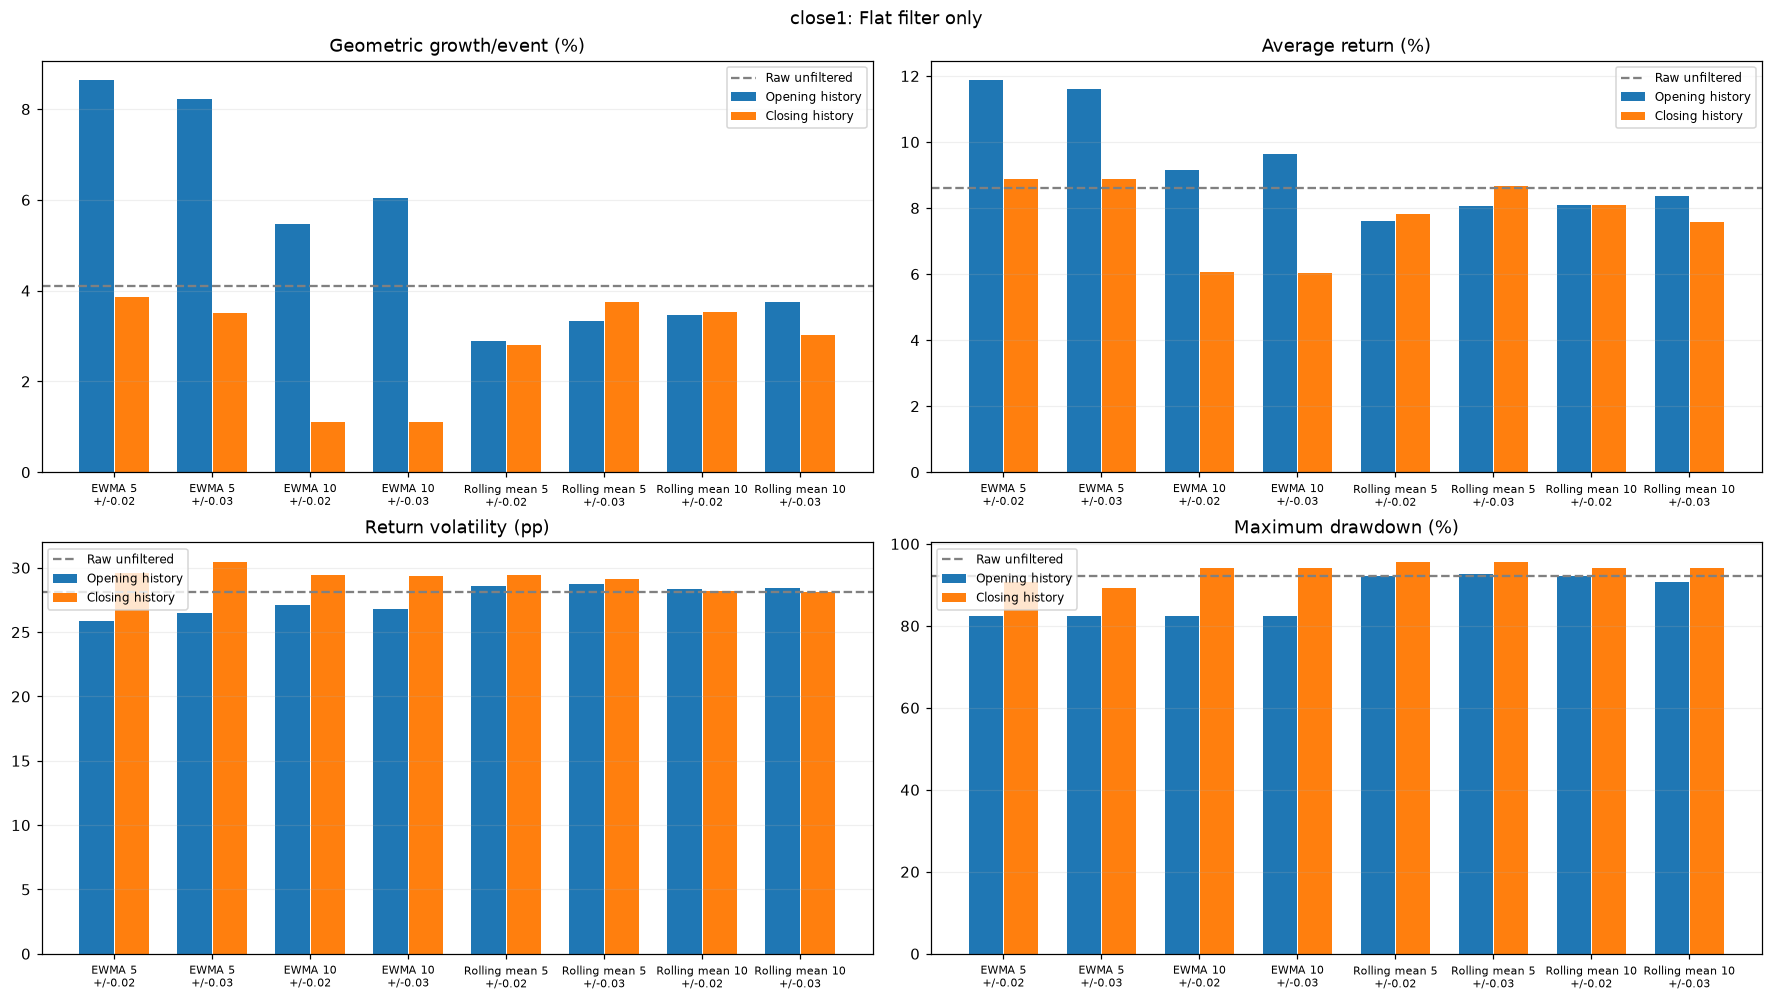

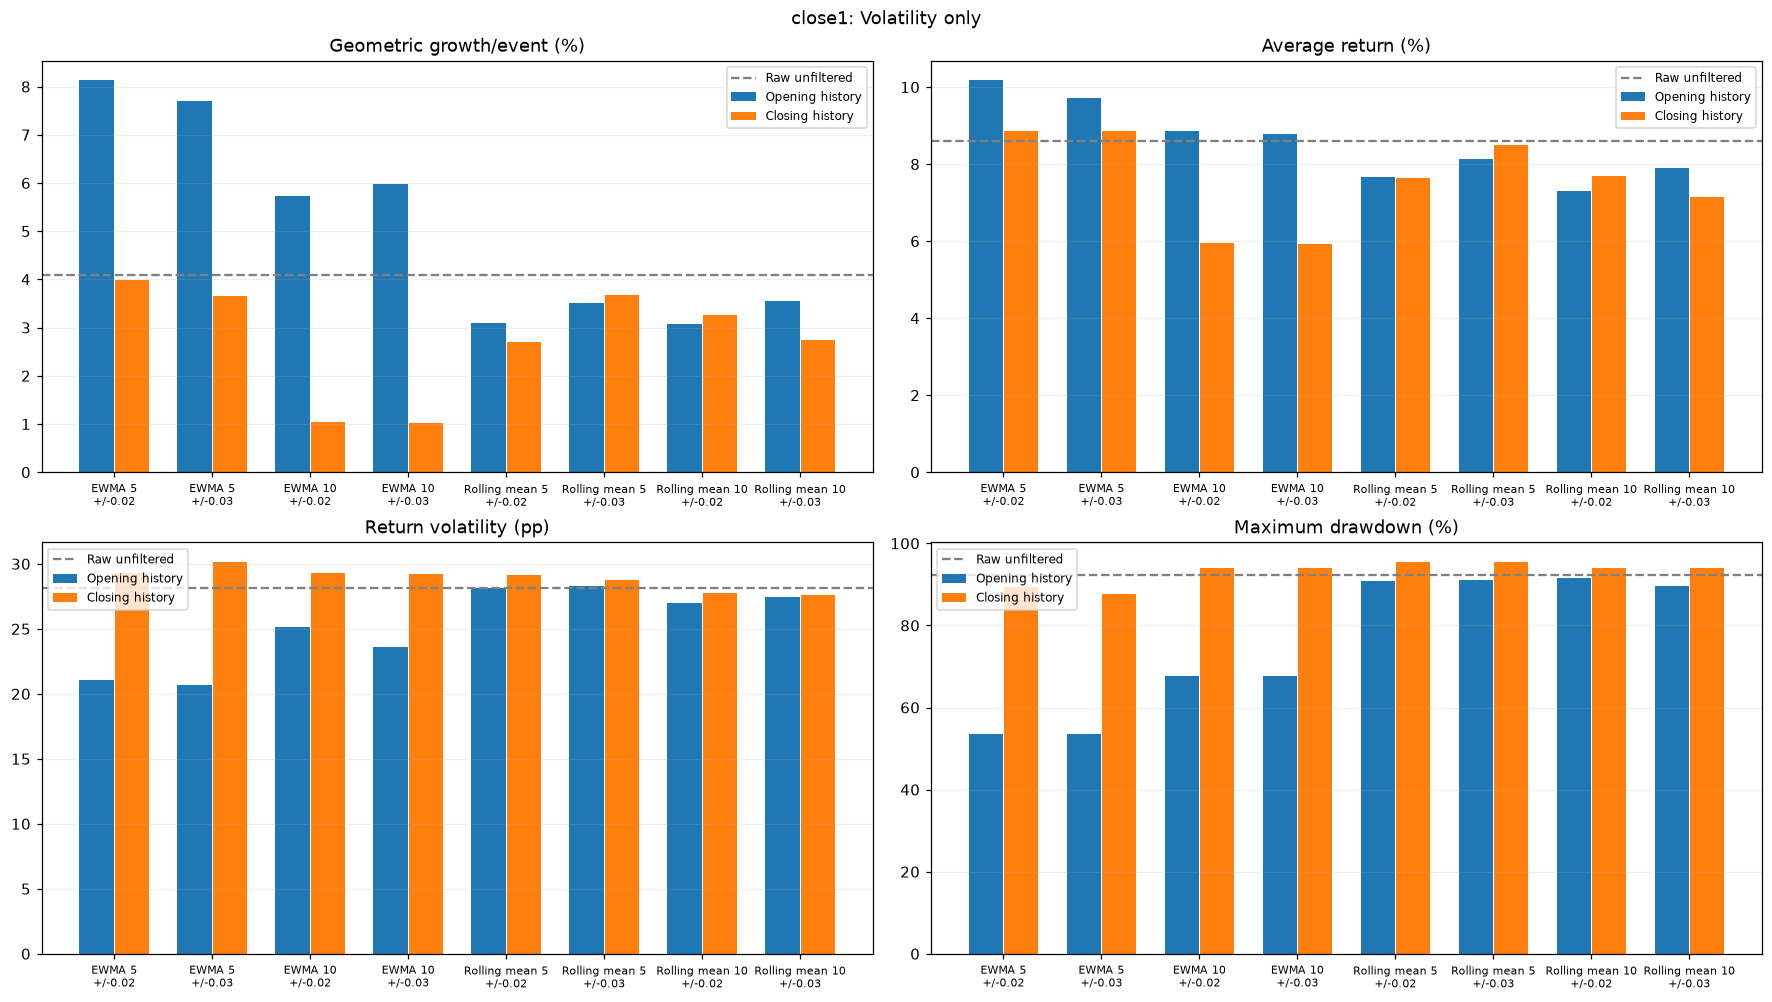

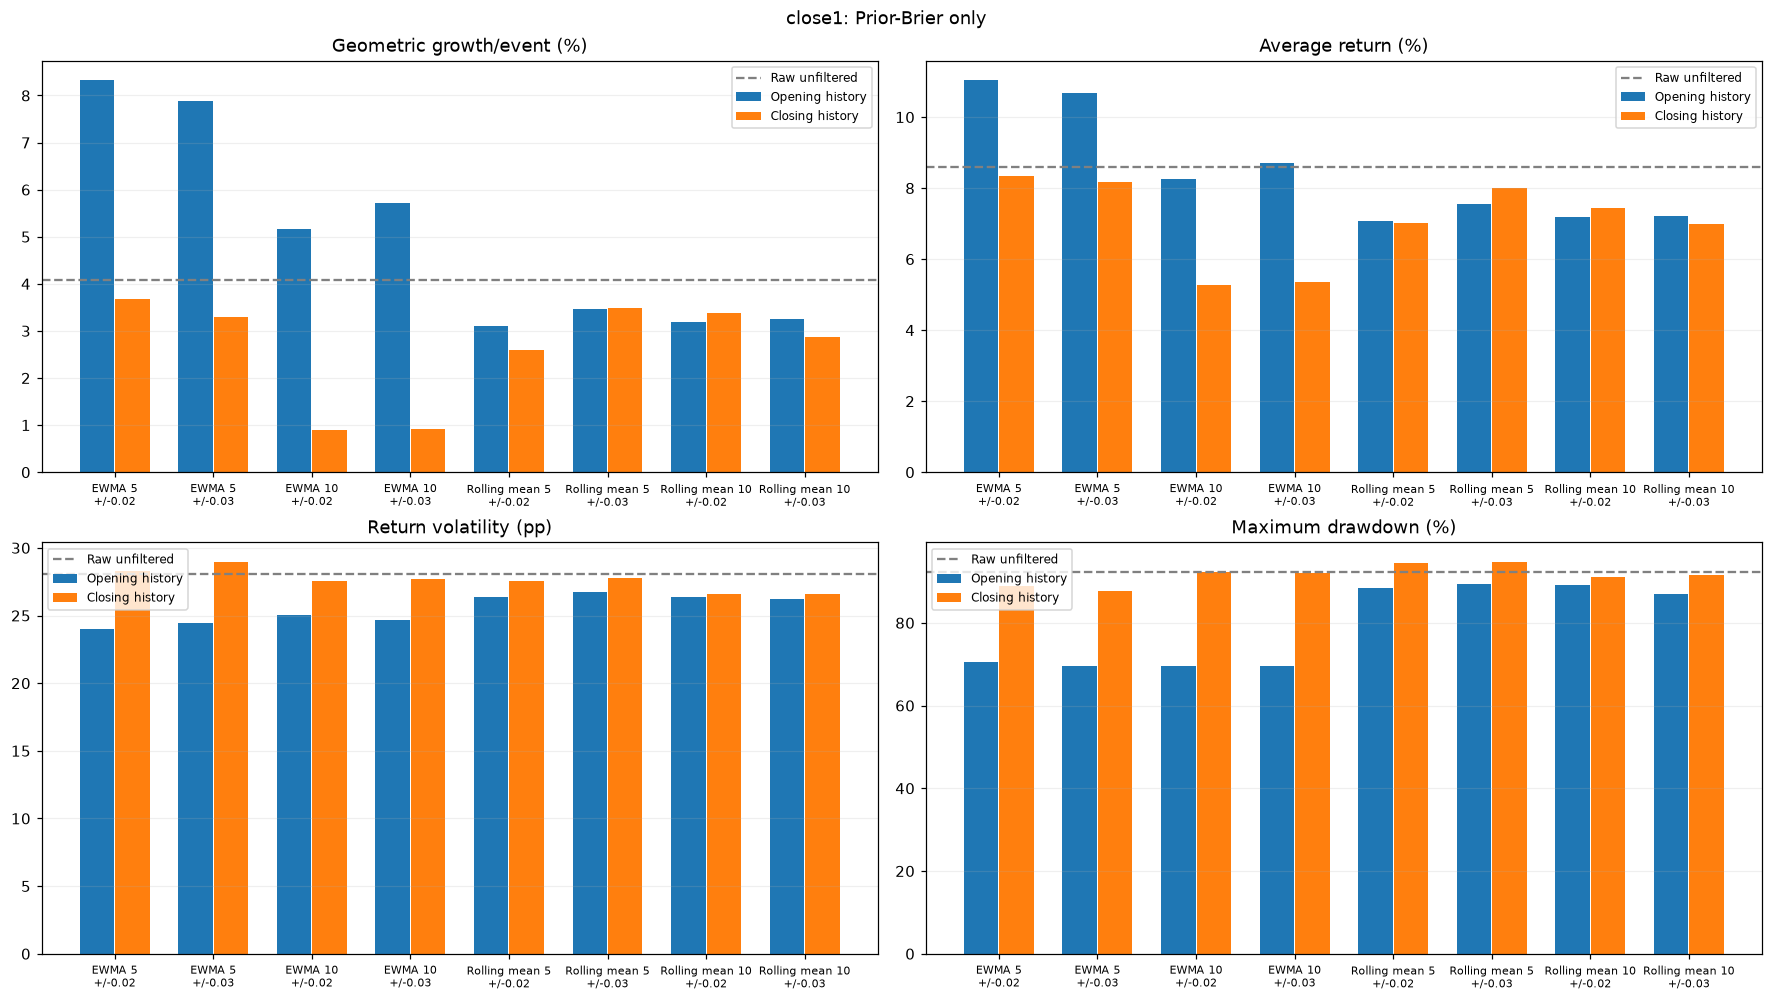

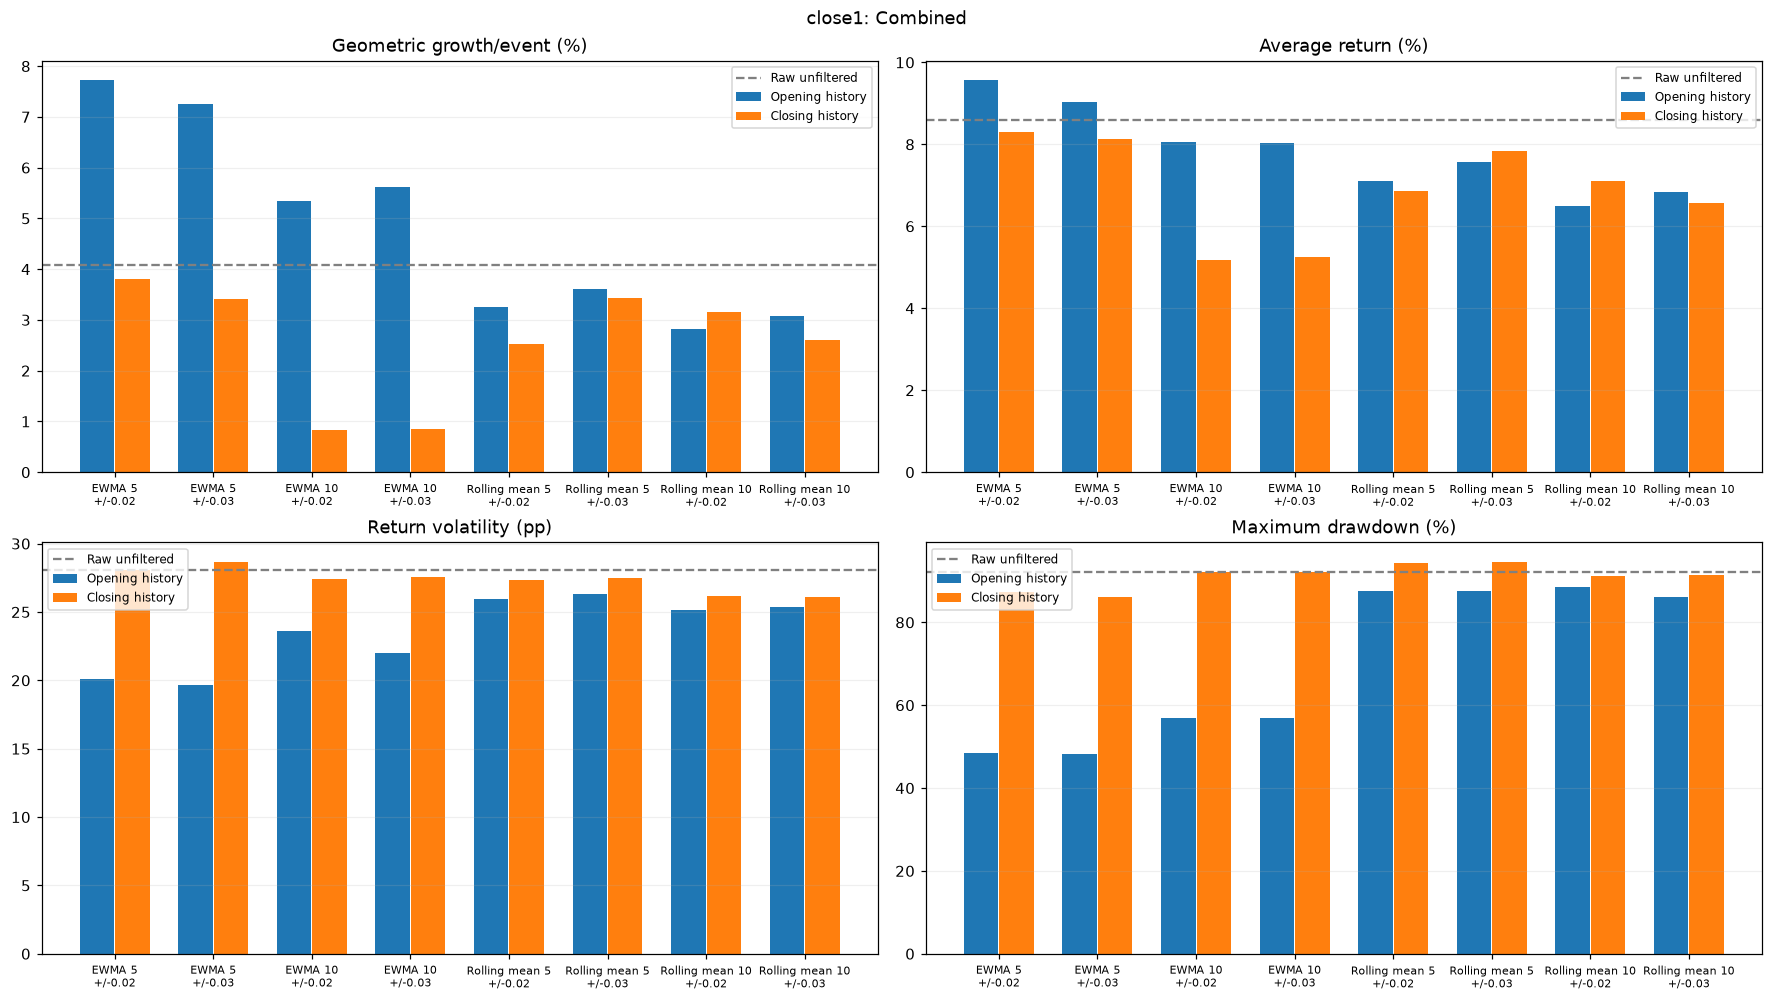

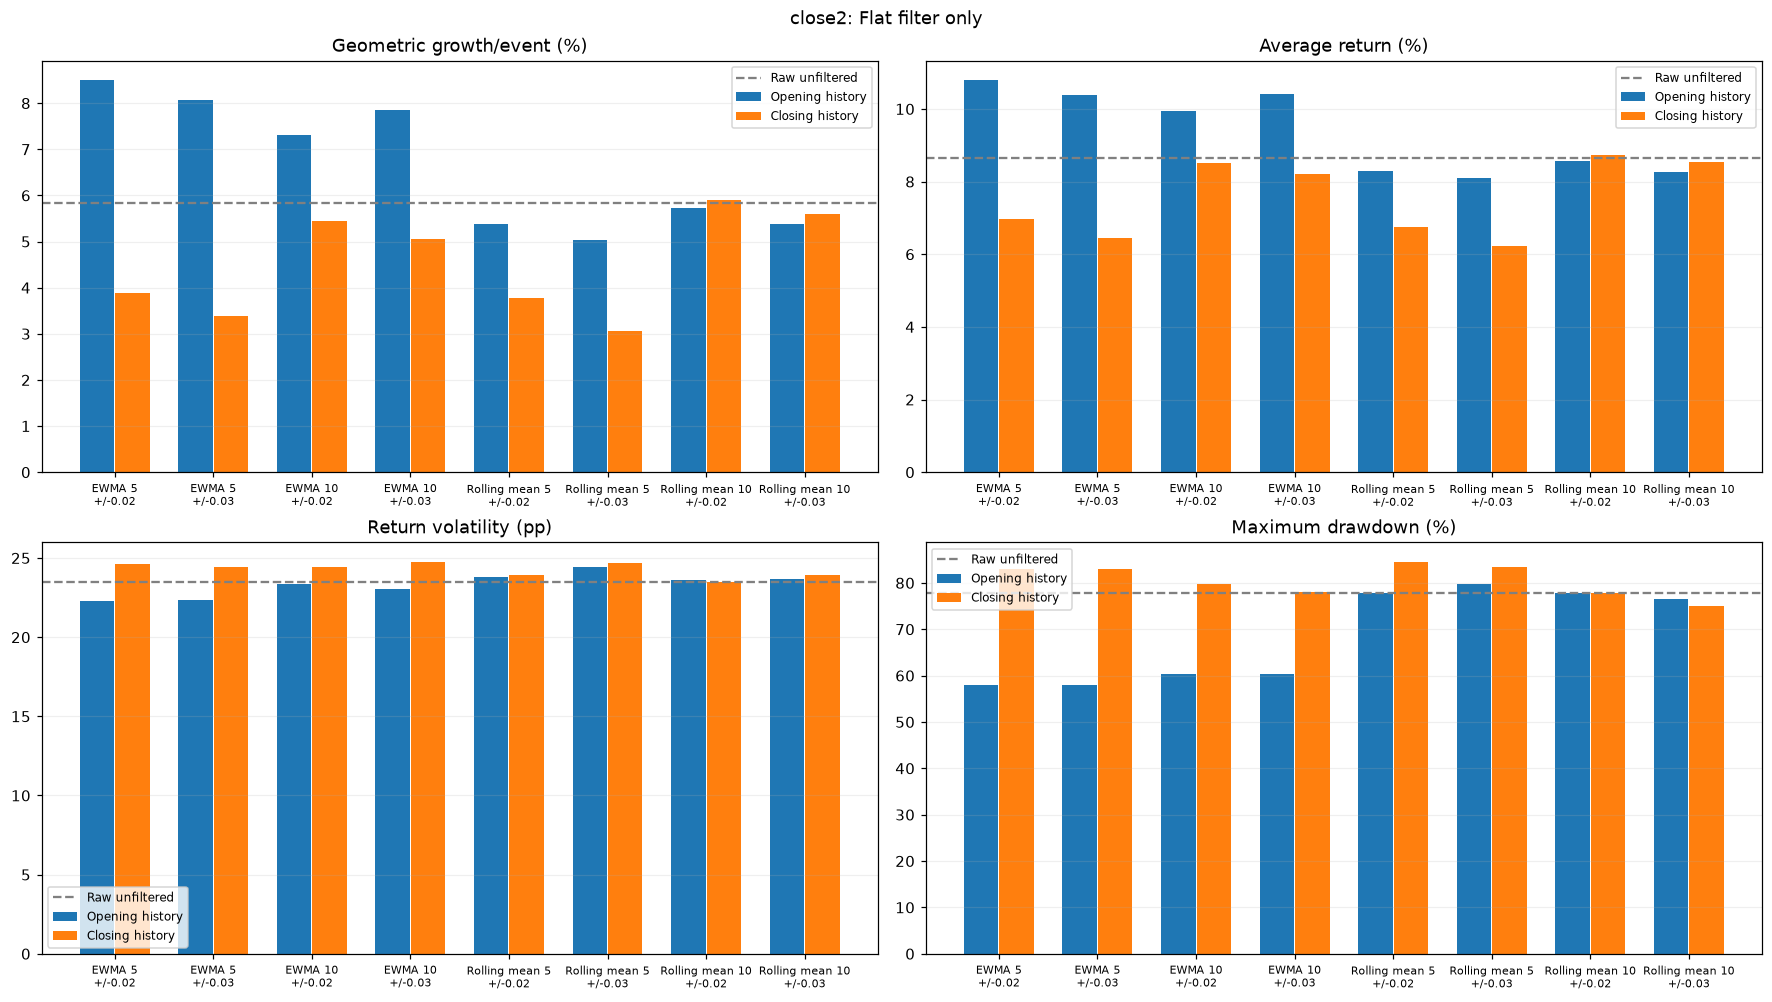

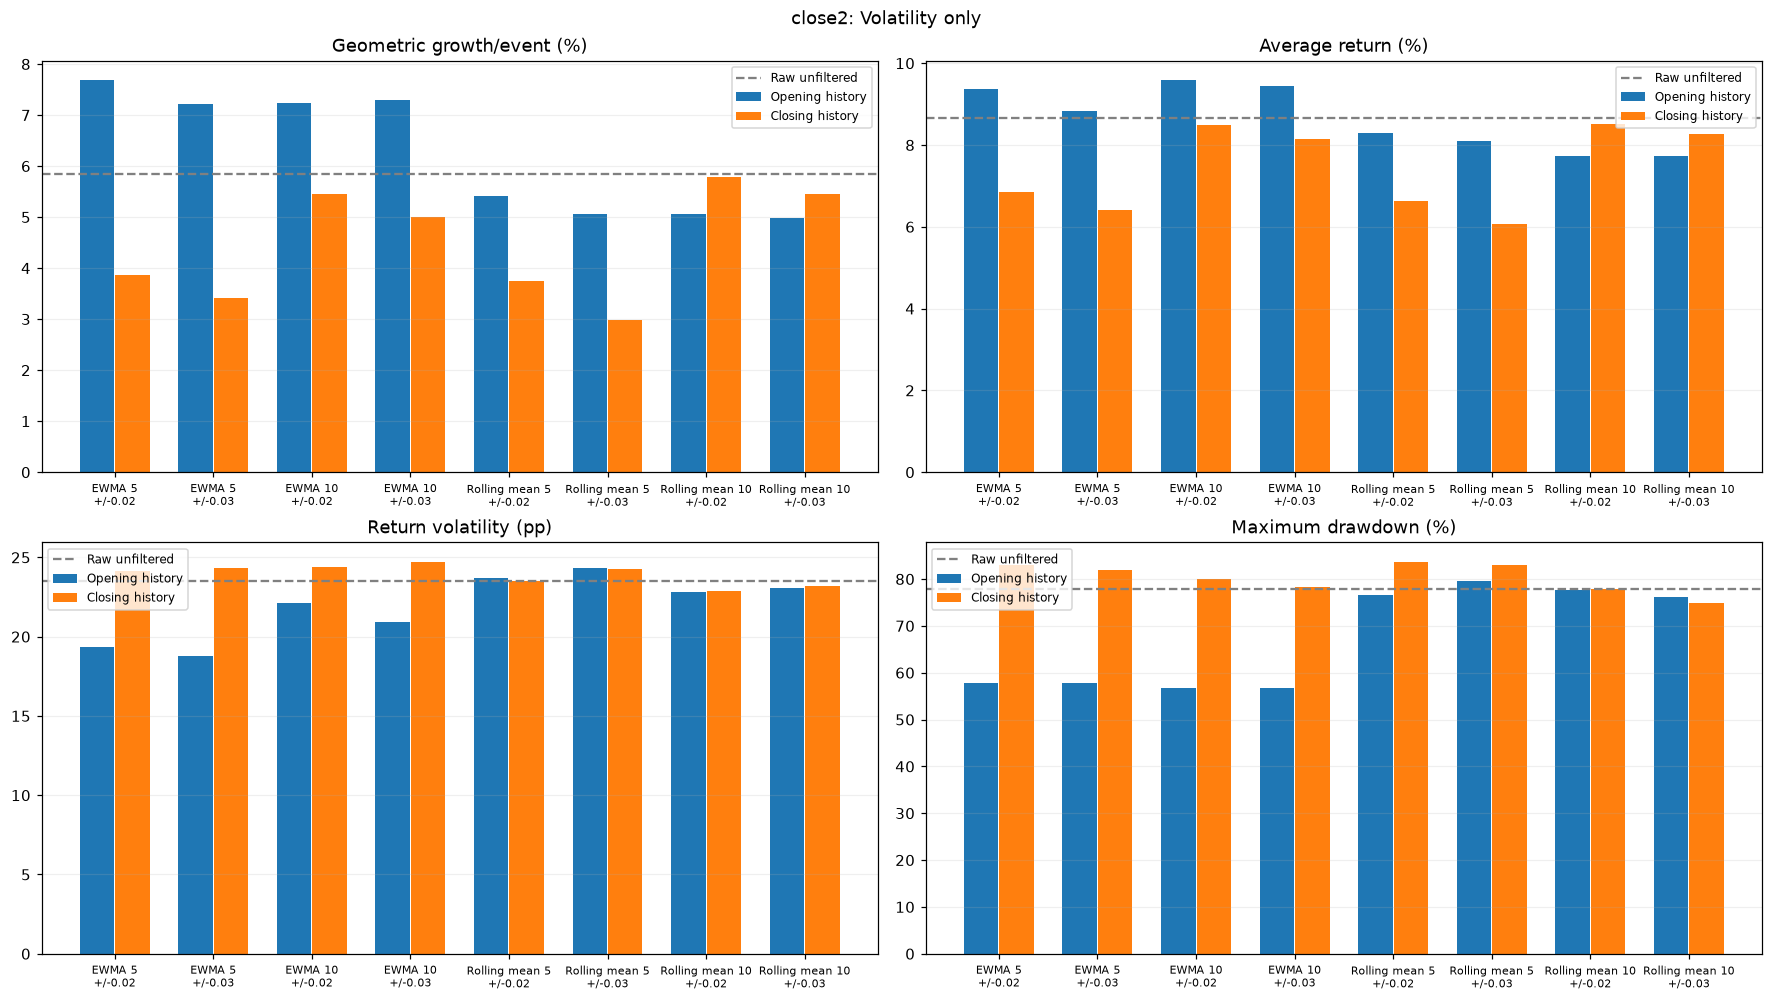

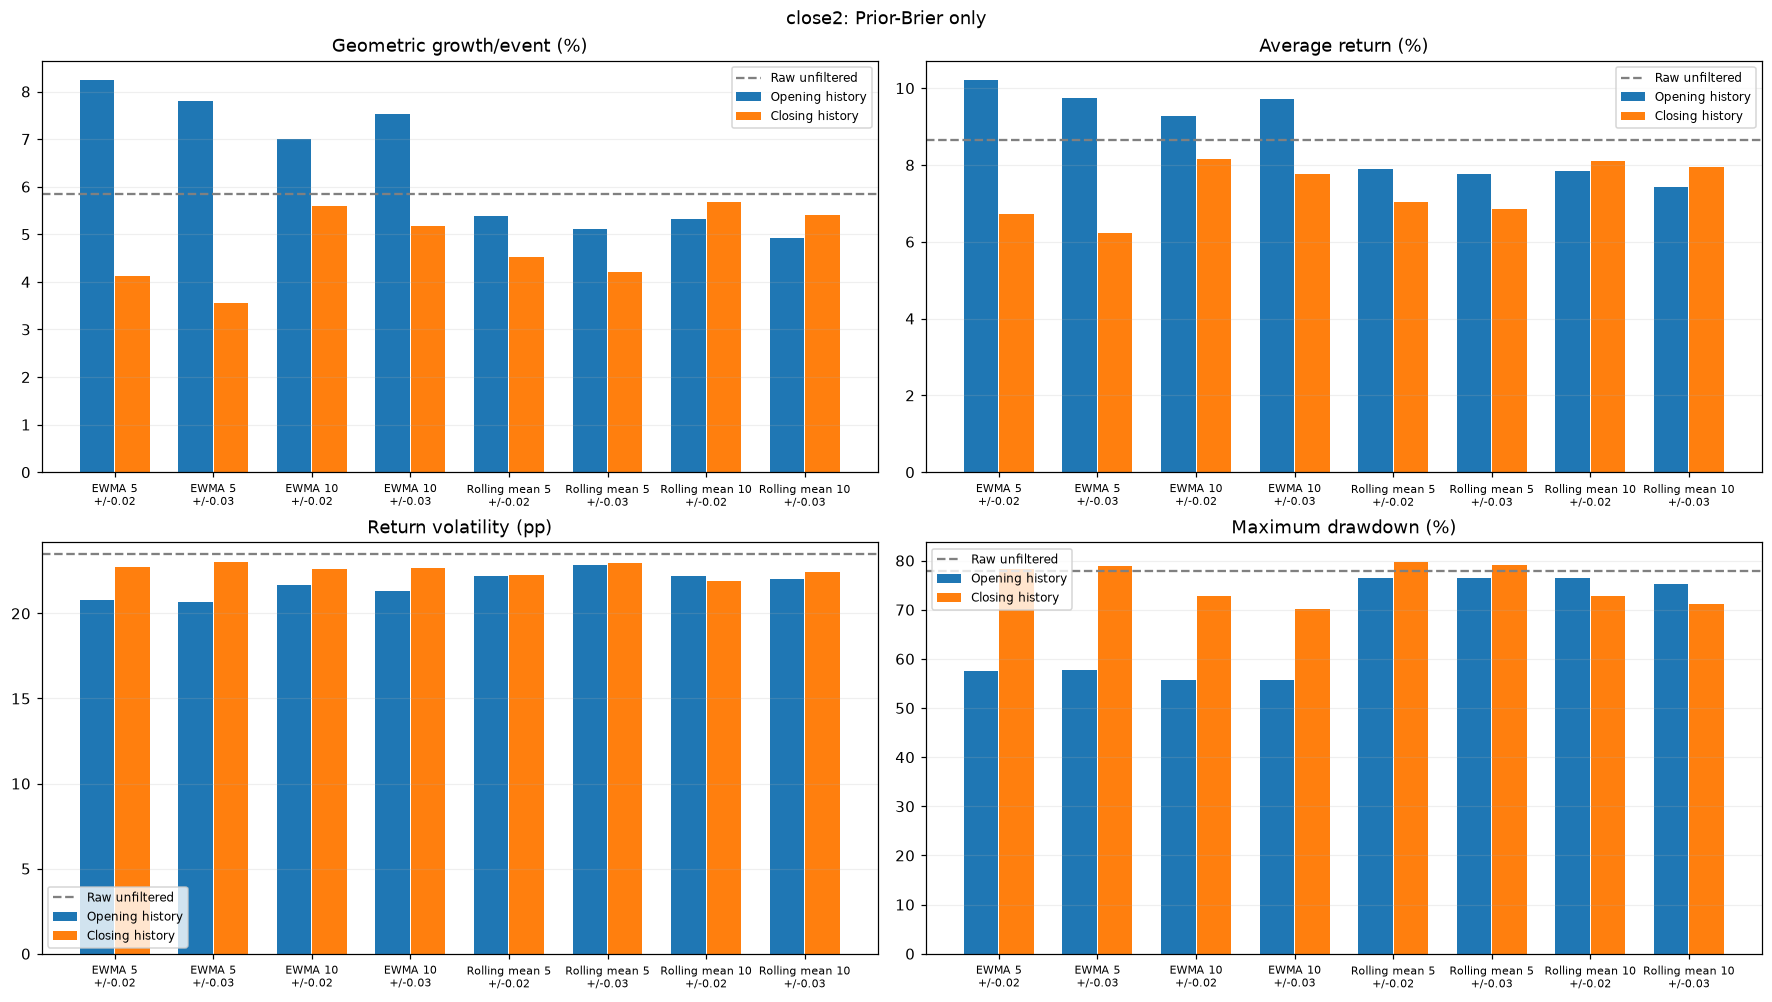

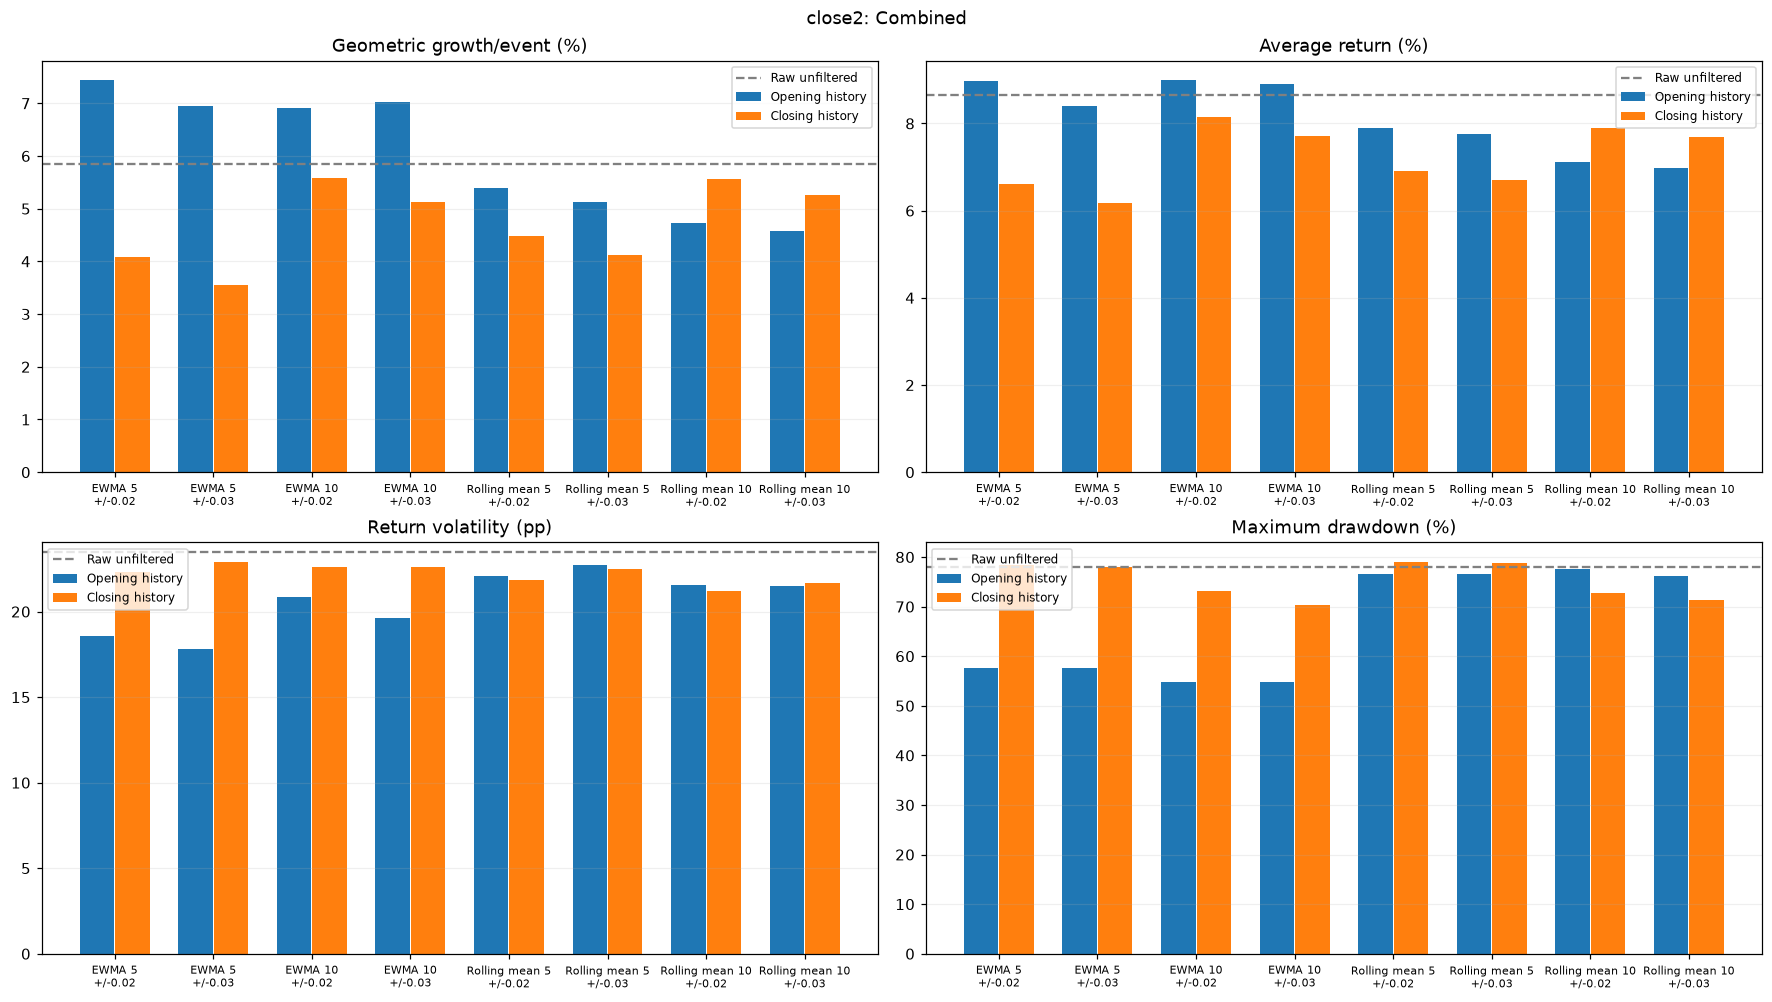

In [3]:
keys=[(m,w,c) for m in ['EWMA','Rolling mean'] for w in [5,10] for c in [.02,.03]]
for market in ['close1','close2']:
    for strategy in strategies:
        fig,axes=plt.subplots(2,2,figsize=(16,9),constrained_layout=True)
        raw=metrics(source_results[(market,*DETAIL)]['events'].return_pct)
        for ax,metric,title in zip(axes.flat,['geometric_growth_pct','average_return_pct','volatility_pp','max_drawdown_pct'],
                ['Geometric growth/event (%)','Average return (%)','Return volatility (pp)','Maximum drawdown (%)']):
            for offset,label in [(-.18,'Opening history'),(.18,'Closing history')]:
                values=[smoothing_metrics.loc[(smoothing_metrics.market==market)&(smoothing_metrics.history==label)&
                    (smoothing_metrics.smoothing==m)&(smoothing_metrics.window==w)&(smoothing_metrics.cutoff==c)&
                    (smoothing_metrics.period=='Combined')&(smoothing_metrics.strategy==strategy),metric].iloc[0] for m,w,c in keys]
                ax.bar(np.arange(8)+offset,values,.35,label=label)
            ax.axhline(raw[metric],color='gray',ls='--',label='Raw unfiltered')
            ax.set_xticks(range(8),[f'{m} {w}\n+/-{c}' for m,w,c in keys],fontsize=7)
            ax.set_title(title);ax.legend(fontsize=8);ax.grid(axis='y',alpha=.2)
        fig.suptitle(f'{market}: {strategy}');plt.show()


## Event selection versus stake scaling: crossed comparison

EWMA-5, +/-0.02. Holding the gate fixed isolates the source of multipliers; holding scaler source fixed isolates selection. Counts and event-date overlap are reported. No fallback multipliers are filled in for crossed comparisons.

close1 {'both': 79, 'opening_only': 13, 'closing_only': 8, 'neither': 5}
close2 {'both': 77, 'opening_only': 15, 'closing_only': 10, 'neither': 3}
market   gate scalers         strategy  events  geometric_growth_pct  average_return_pct  volatility_pp  worst_event_pct  max_drawdown_pct  final_wealth
close1   open    open Flat filter only      92                8.6303             11.8633        25.8778         -55.8002           82.2972     2029.9315
close1   open    open  Volatility only      92                8.1263             10.1705        21.0325         -50.7667           53.6023     1323.3270
close1   open    open Prior-Brier only      92                8.3186             11.0304        24.0266         -47.4316           70.4486     1558.4375
close1   open    open         Combined      92                7.7172              9.5578        20.1330         -47.4316           48.4352      933.7209
close1   open  close1 Flat filter only      92                8.6303             11.8633

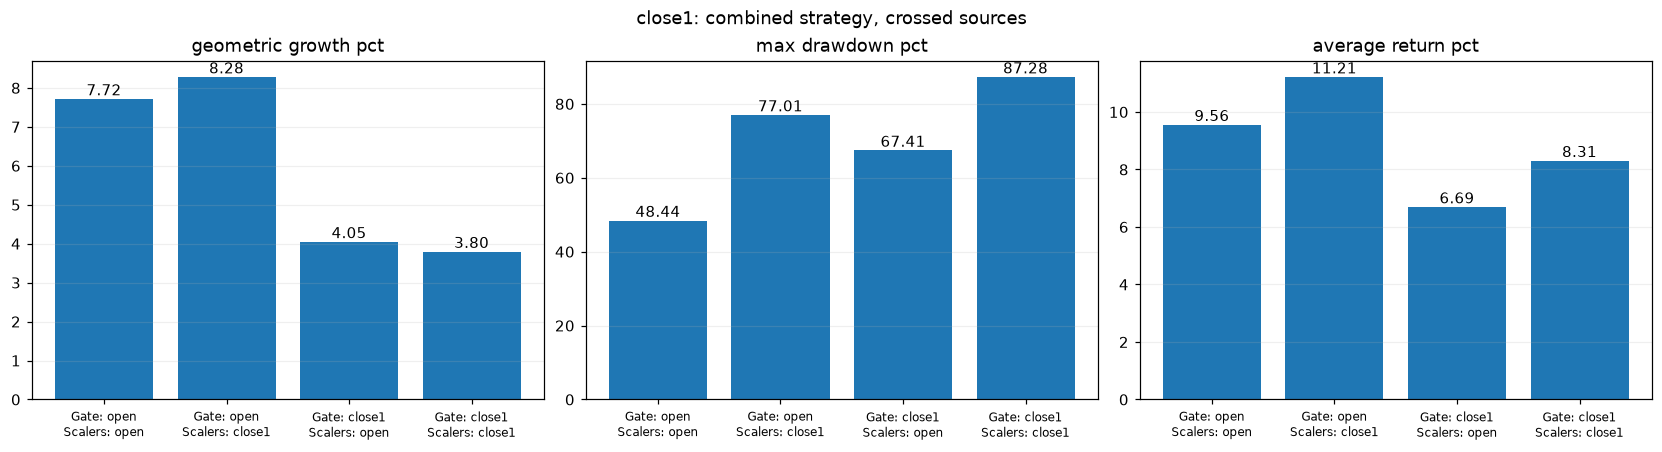

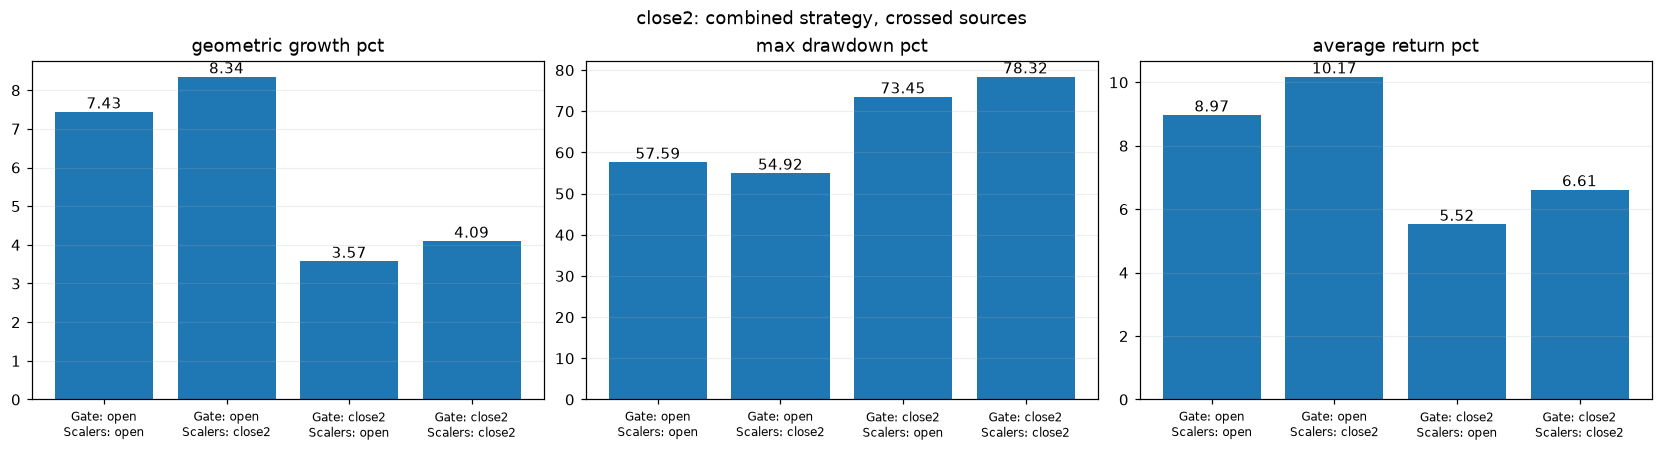

In [4]:
cross_rows=[]
for market in ['close1','close2']:
    for gate in ['open',market]:
        for scaler in ['open',market]:
            result=apply_sources(market,gate,scaler,DETAIL)
            for strategy in strategies:
                cross_rows.append(dict(market=market,gate=gate,scalers=scaler,strategy=strategy,
                    **metrics(result['returns'].loc[result['keep'],strategy])))
    a=comparison_results[(market,'Opening history',*DETAIL)]['keep']
    b=comparison_results[(market,'Closing history',*DETAIL)]['keep']
    print(market,dict(both=int((a&b).sum()),opening_only=int((a&~b).sum()),closing_only=int((~a&b).sum()),neither=int((~a&~b).sum())))
cross_metrics=pd.DataFrame(cross_rows)
print(cross_metrics.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
for market in ['close1','close2']:
    part=cross_metrics.loc[(cross_metrics.market==market)&(cross_metrics.strategy=='Combined')]
    fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
    for ax,col in zip(axes,['geometric_growth_pct','max_drawdown_pct','average_return_pct']):
        bars=ax.bar(np.arange(4),part[col]);ax.bar_label(bars,fmt='%.2f')
        ax.set_xticks(range(4),[f'Gate: {r.gate}\nScalers: {r.scalers}' for r in part.itertuples()],fontsize=8)
        ax.set_title(col.replace('_',' '));ax.grid(axis='y',alpha=.2)
    fig.suptitle(f'{market}: combined strategy, crossed sources');plt.show()


## Effect per event and bankroll from 500

Same dates and raw closing-return baseline for both sources. Effect is scaled return minus raw return on selected events; skipped events are omitted from effect bars (not presented as scaling savings). Bankroll plots include all dates with zero return when skipped. Each validation/test period starts at 500.

market         history     period         strategy  ending_bankroll
close1 Opening history Validation   Raw unfiltered     48672.623006
close1 Opening history Validation Flat filter only    146919.973505
close1 Opening history Validation  Volatility only    128533.880666
close1 Opening history Validation Prior-Brier only    121853.340545
close1 Opening history Validation         Combined    106766.847593
close1 Opening history       Test   Raw unfiltered       346.131814
close1 Opening history       Test Flat filter only      3454.144956
close1 Opening history       Test  Volatility only      2573.887500
close1 Opening history       Test Prior-Brier only      3197.363201
close1 Opening history       Test         Combined      2186.354957
close1 Closing history Validation   Raw unfiltered     48672.623006
close1 Closing history Validation Flat filter only     19504.021822
close1 Closing history Validation  Volatility only     19194.774715
close1 Closing history Validation Prior-Brier on

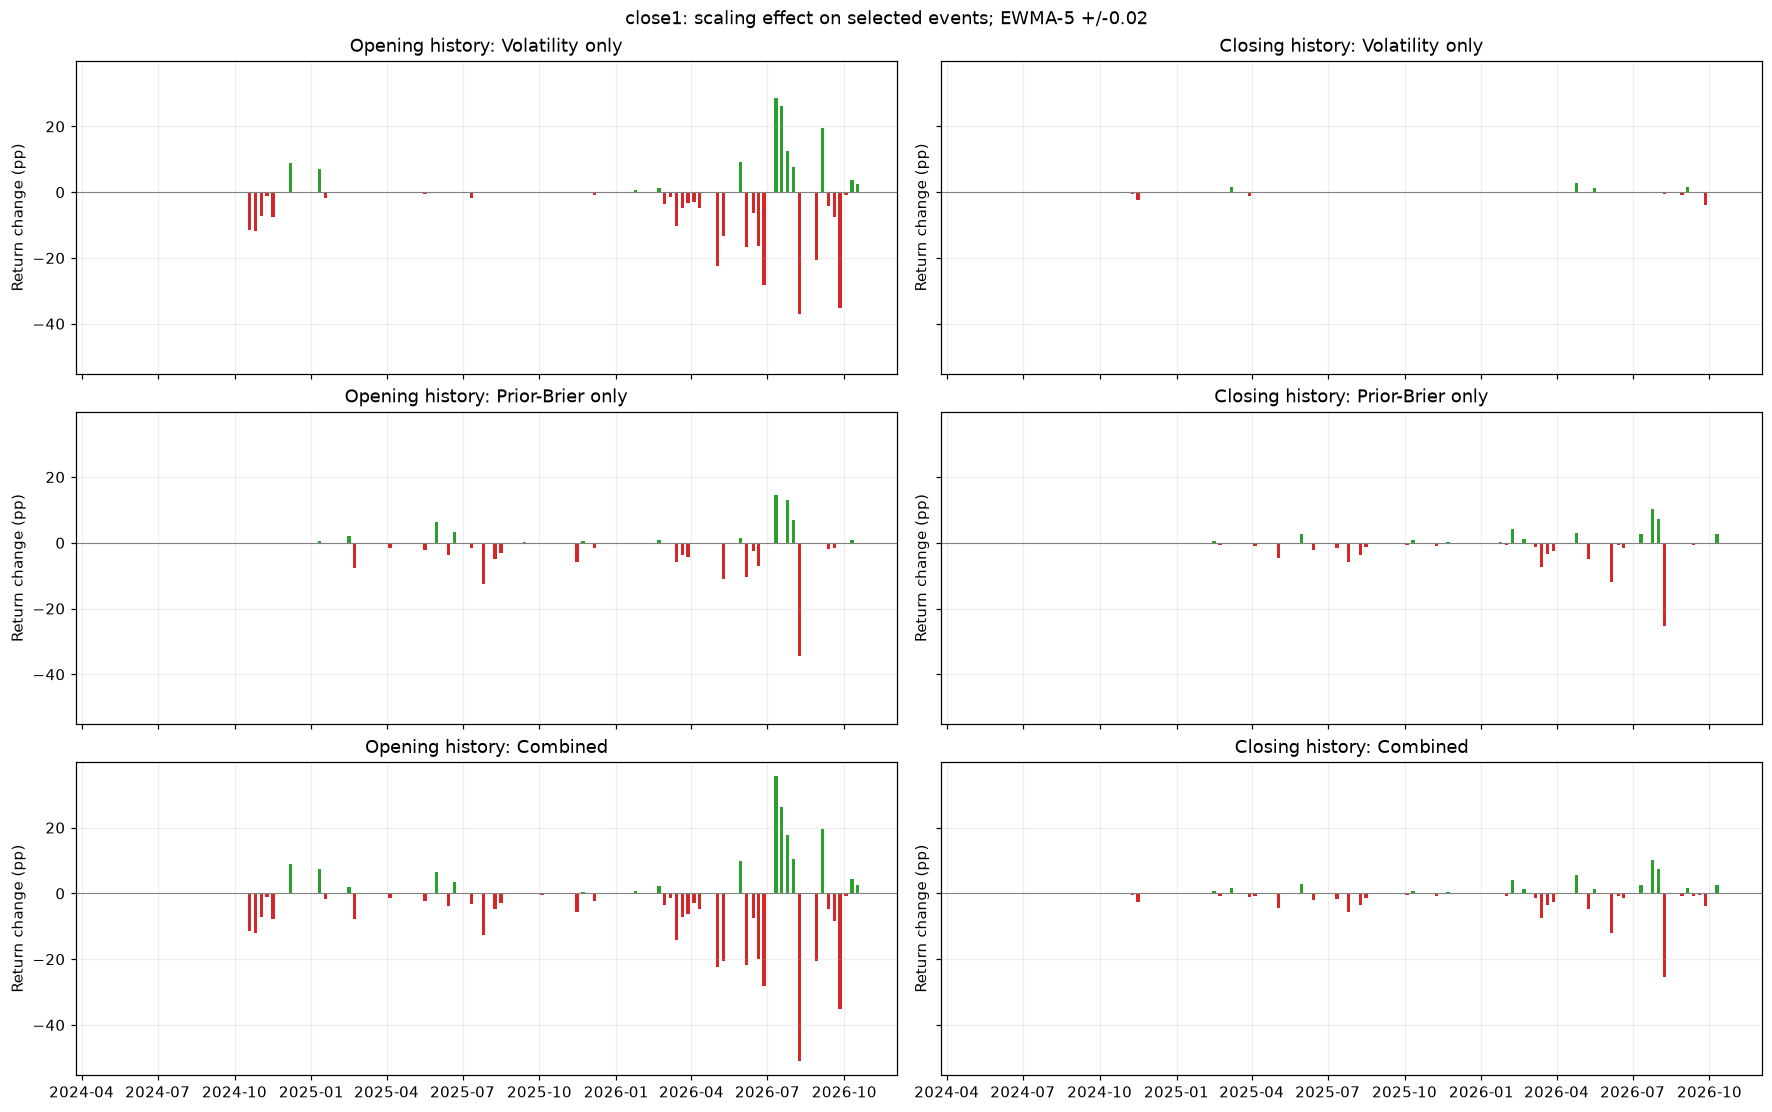

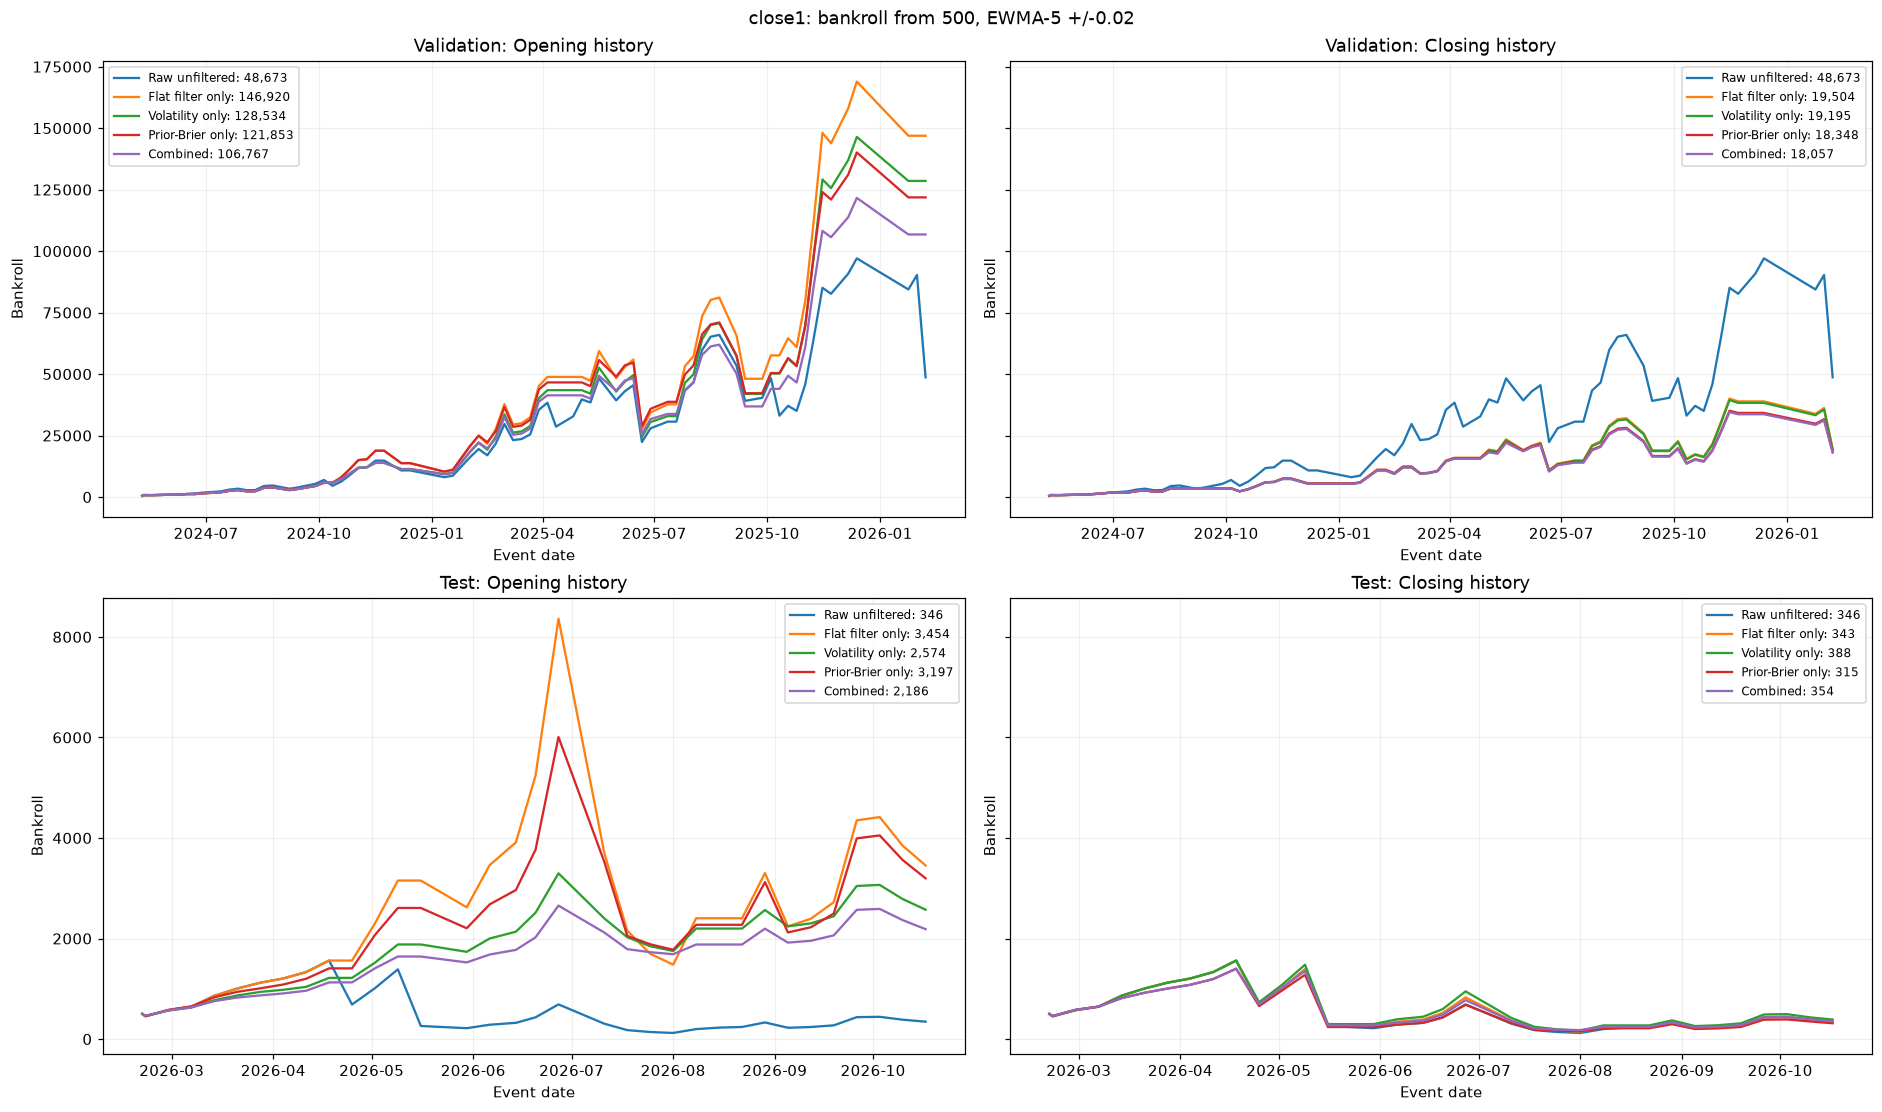

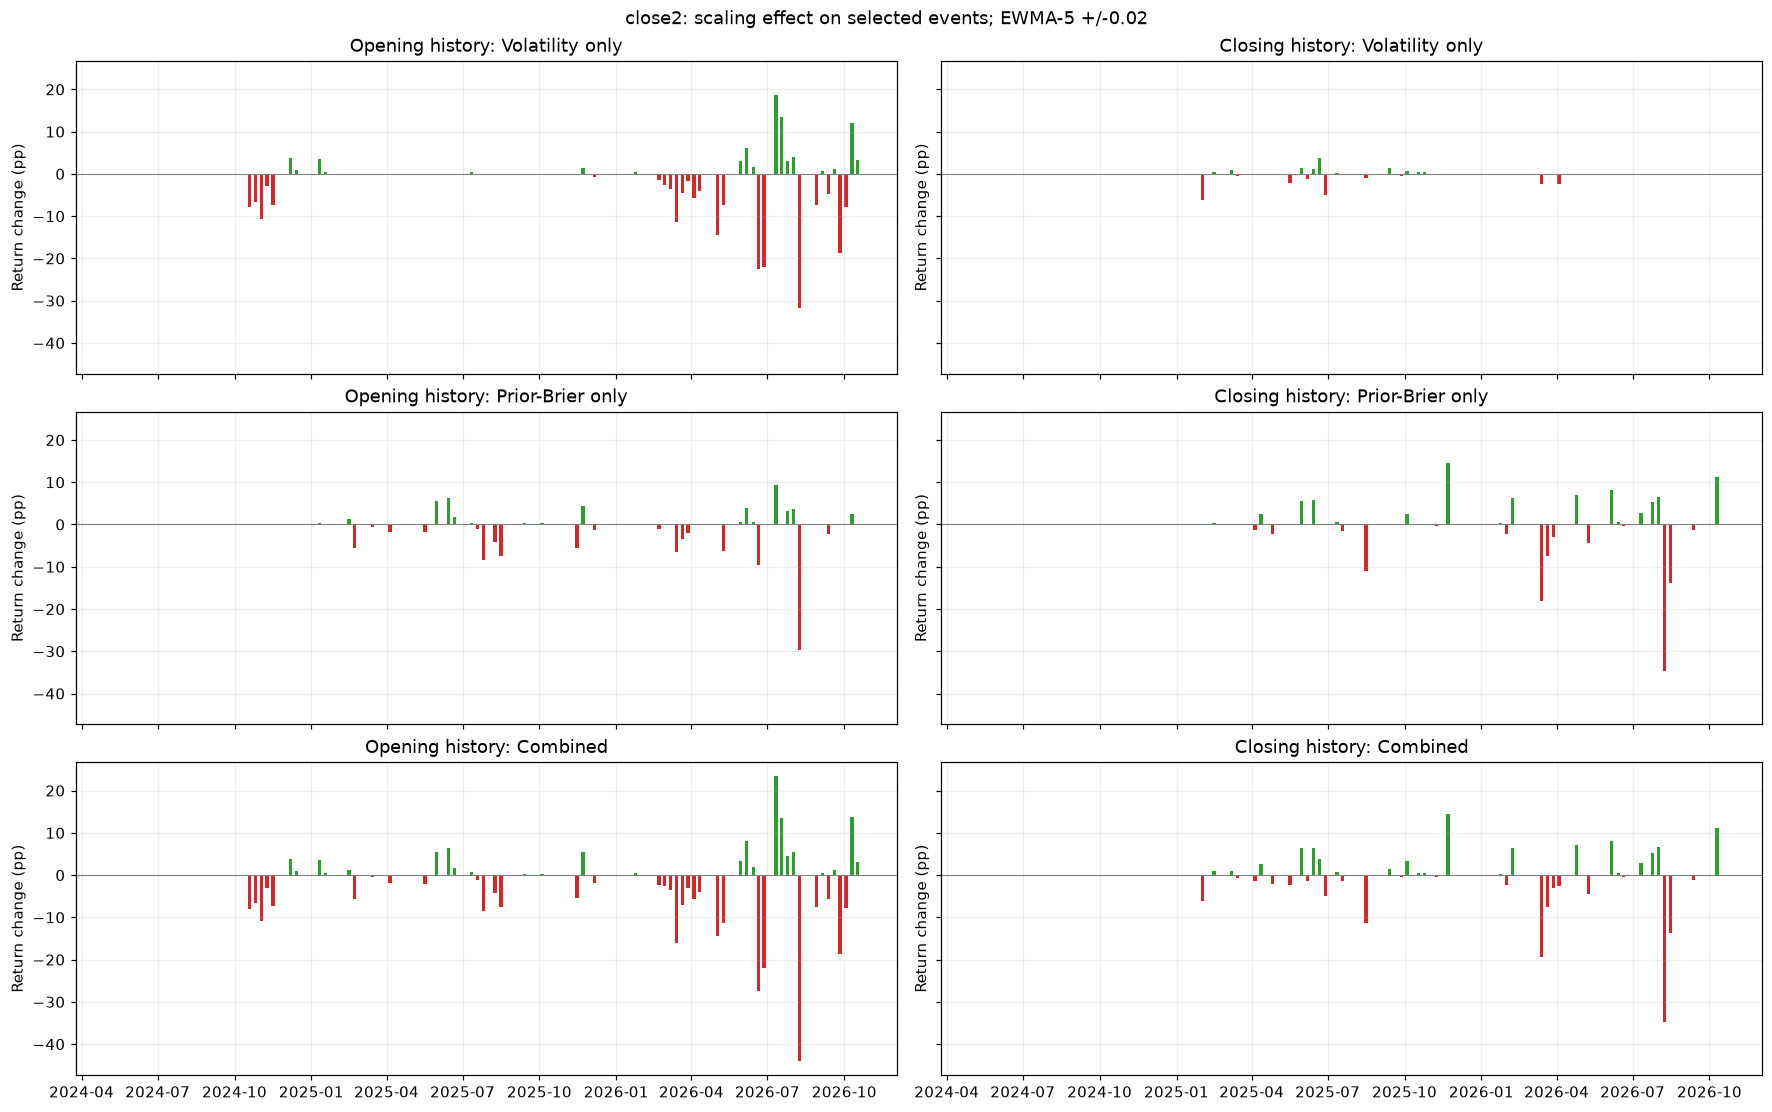

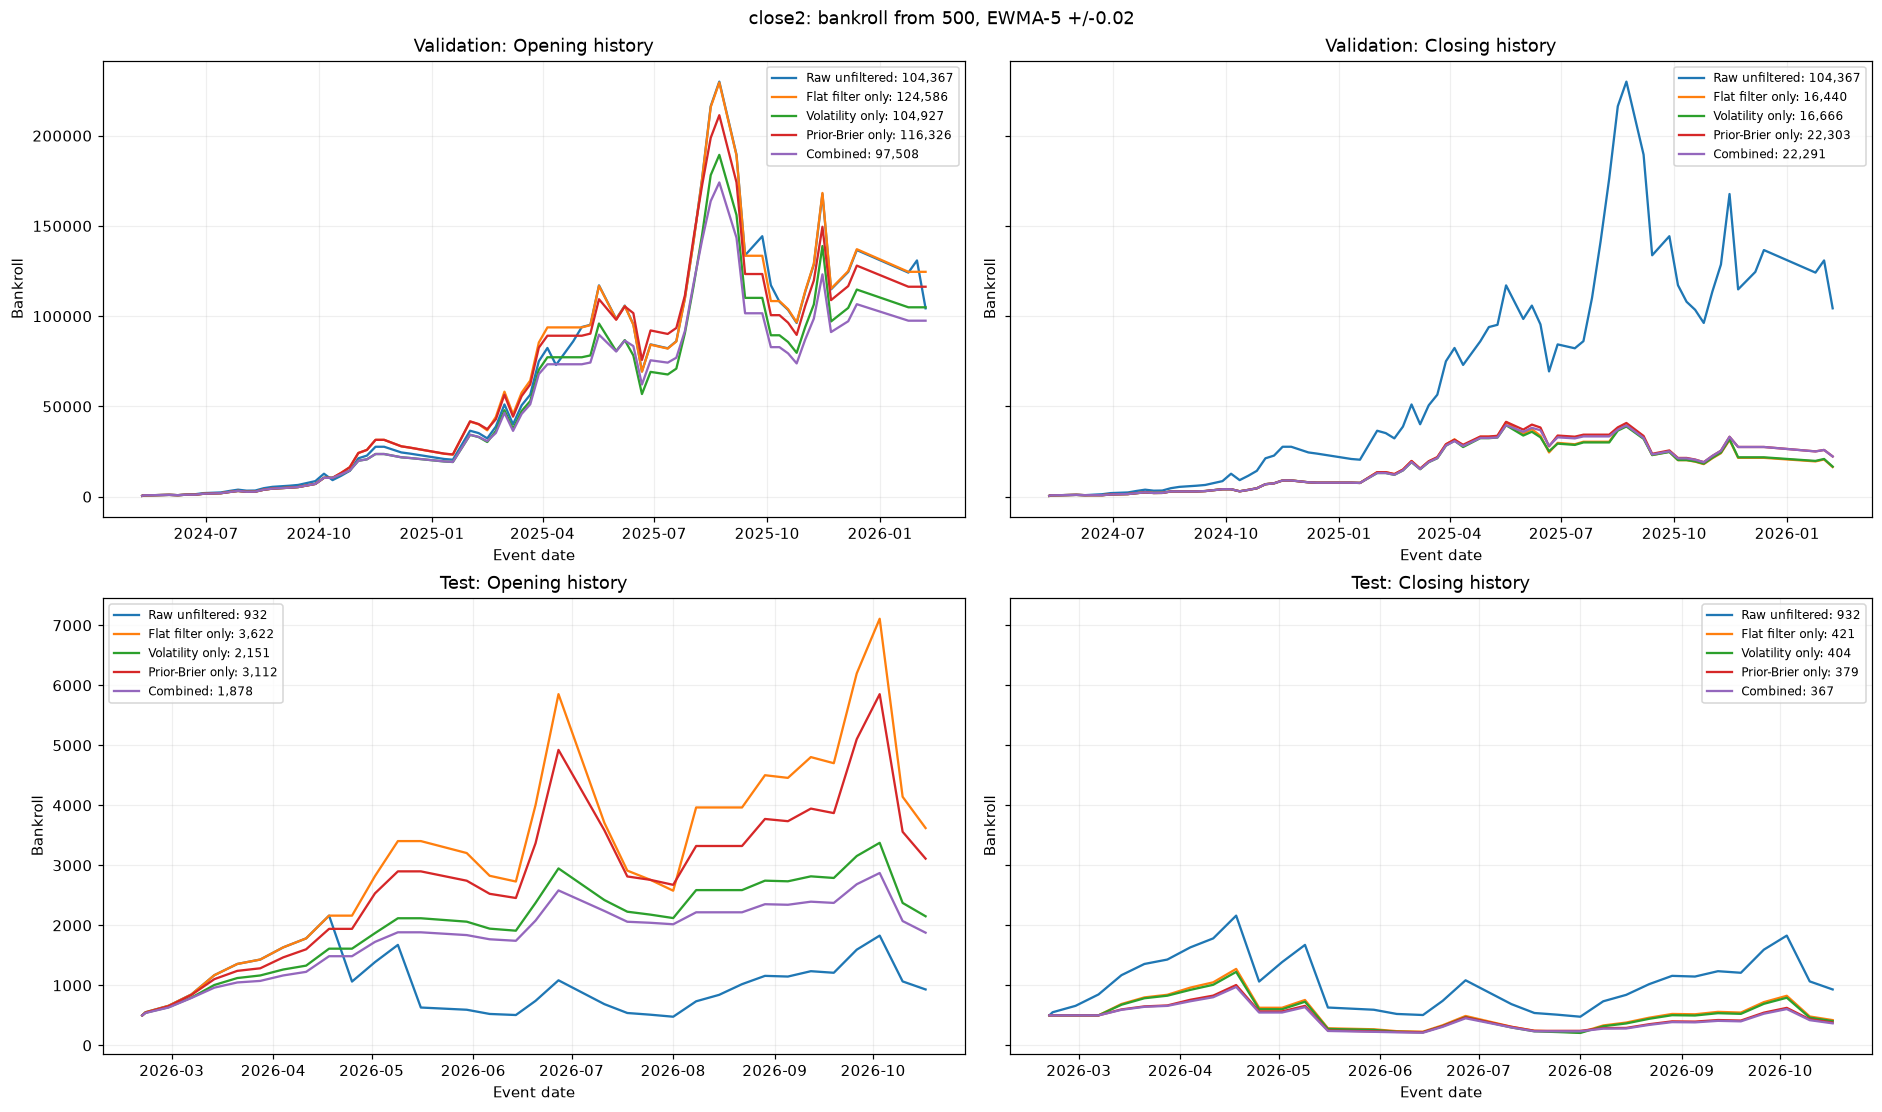

In [5]:
bankroll_rows=[]
for market in ['close1','close2']:
    fig,axes=plt.subplots(3,2,figsize=(16,10),sharex=True,sharey=True,constrained_layout=True)
    for col,source in enumerate(['Opening history','Closing history']):
        result=comparison_results[(market,source,*DETAIL)]
        for ax,strategy in zip(axes[:,col],strategies[1:]):
            active=result['returns'].loc[result['keep']]
            effect=active[strategy]-active['Raw unfiltered']
            ax.bar(effect.index,effect,width=4,color=np.where(effect>=0,'tab:green','tab:red'))
            ax.axhline(0,color='gray',lw=.7);ax.set(title=f'{source}: {strategy}',ylabel='Return change (pp)');ax.grid(alpha=.2)
    fig.suptitle(f'{market}: scaling effect on selected events; EWMA-5 +/-0.02');plt.show()
    fig,axes=plt.subplots(2,2,figsize=(17,10),sharey='row',constrained_layout=True)
    for col,source in enumerate(['Opening history','Closing history']):
        result=comparison_results[(market,source,*DETAIL)]
        for row,period in enumerate(['Validation','Test']):
            dates=result['events'].index[result['events'].split.eq(period)];ax=axes[row,col]
            for strategy in ['Raw unfiltered',*strategies]:
                returns=result['returns'].loc[dates,strategy]
                path=pd.Series(np.r_[500.,500*(1+returns/100).cumprod()],index=[dates.min()-pd.Timedelta(days=1),*dates])
                ax.plot(path.index,path,label=f'{strategy}: {path.iloc[-1]:,.0f}')
                bankroll_rows.append(dict(market=market,history=source,period=period,strategy=strategy,ending_bankroll=path.iloc[-1]))
            ax.set(title=f'{period}: {source}',ylabel='Bankroll',xlabel='Event date');ax.legend(fontsize=8);ax.grid(alpha=.2)
    fig.suptitle(f'{market}: bankroll from 500, EWMA-5 +/-0.02');plt.show()
bankroll_summary=pd.DataFrame(bankroll_rows)
print(bankroll_summary.to_string(index=False))


## Raw return distributions and event accuracy by source-defined group

All events, including flats; raw closing returns. Accuracy is positive-return events divided by all events in that group, including zero returns in the denominator. Each figure compares classifications from opening versus closing history, with separate winning/losing distributions. Points have no connecting lines. Mean-group bars also include all events.

market         history        regime     trend  events  wins  losses  zeros  accuracy_pct
close1 Opening history    Above mean      Flat       6     2       4      0     33.333333
close1 Opening history At/below mean      Flat       7     5       2      0     71.428571
close1 Closing history    Above mean      Flat      11     8       3      0     72.727273
close1 Closing history At/below mean      Flat       7     5       1      1     71.428571
close1 Opening history    Above mean   Uptrend      32    25       6      1     78.125000
close1 Opening history At/below mean   Uptrend      10     7       3      0     70.000000
close1 Closing history    Above mean   Uptrend      26    18       7      1     69.230769
close1 Closing history At/below mean   Uptrend      14    12       2      0     85.714286
close1 Opening history    Above mean Downtrend      15    12       3      0     80.000000
close1 Opening history At/below mean Downtrend      35    22      12      1     62.857143
close1 Clo

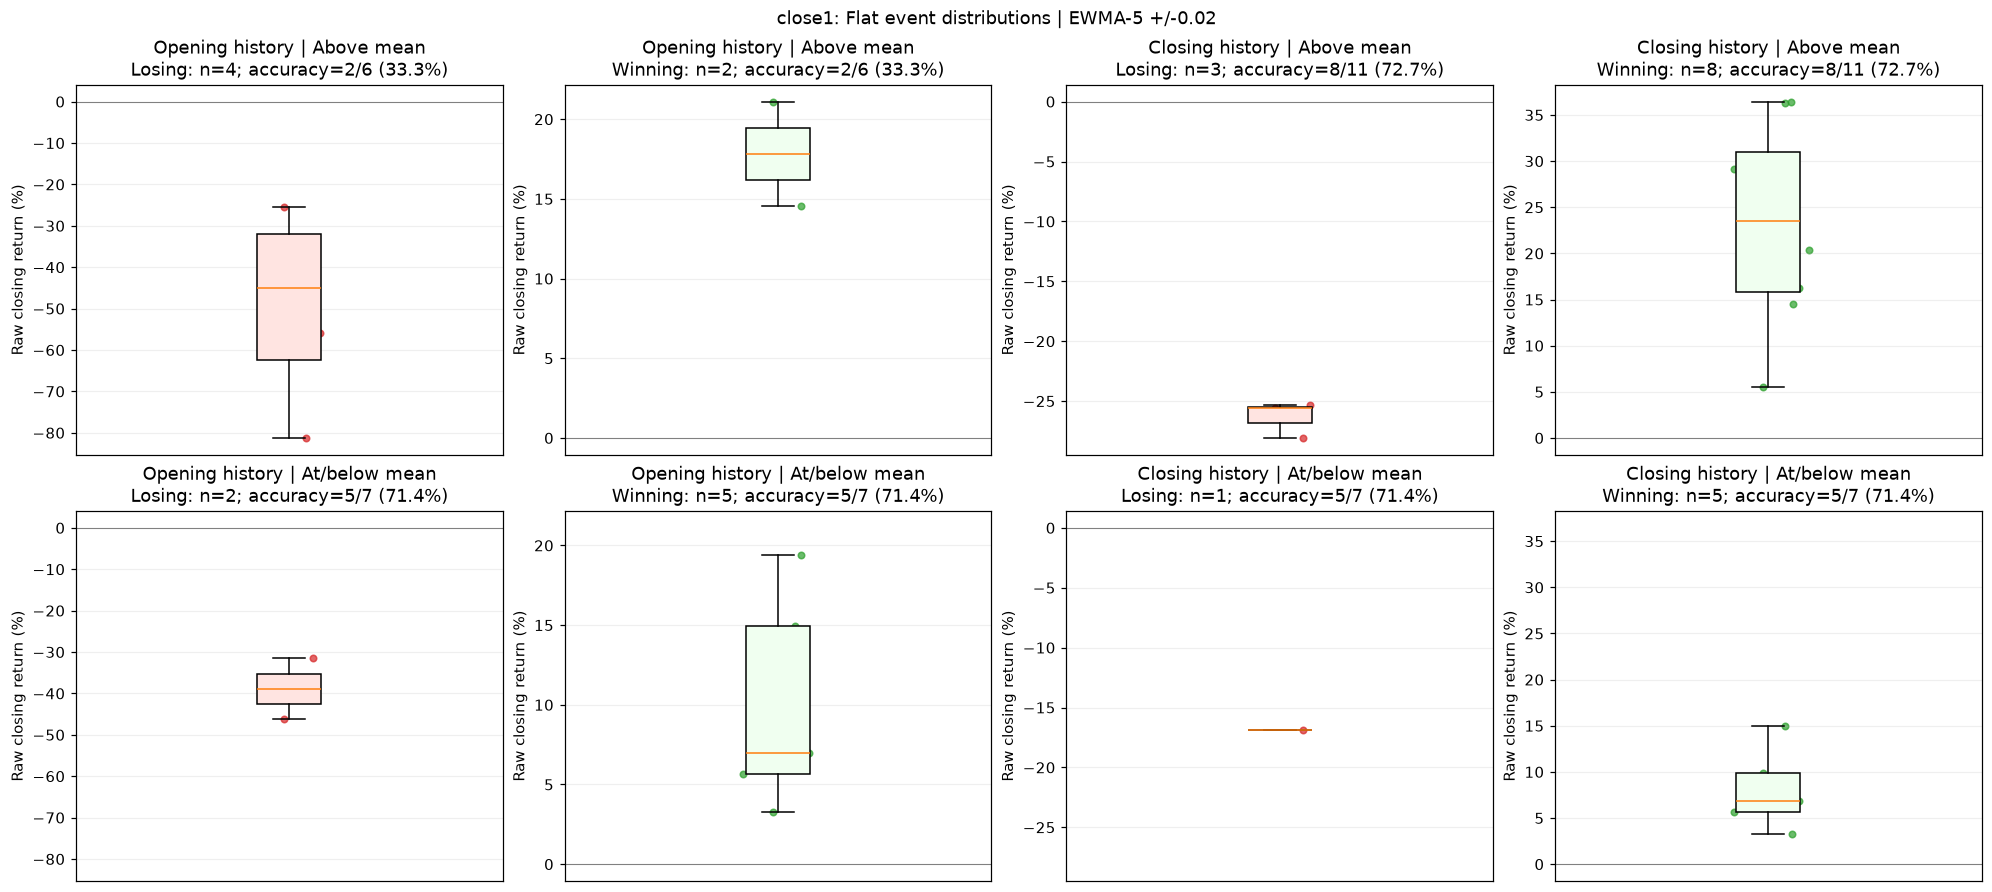

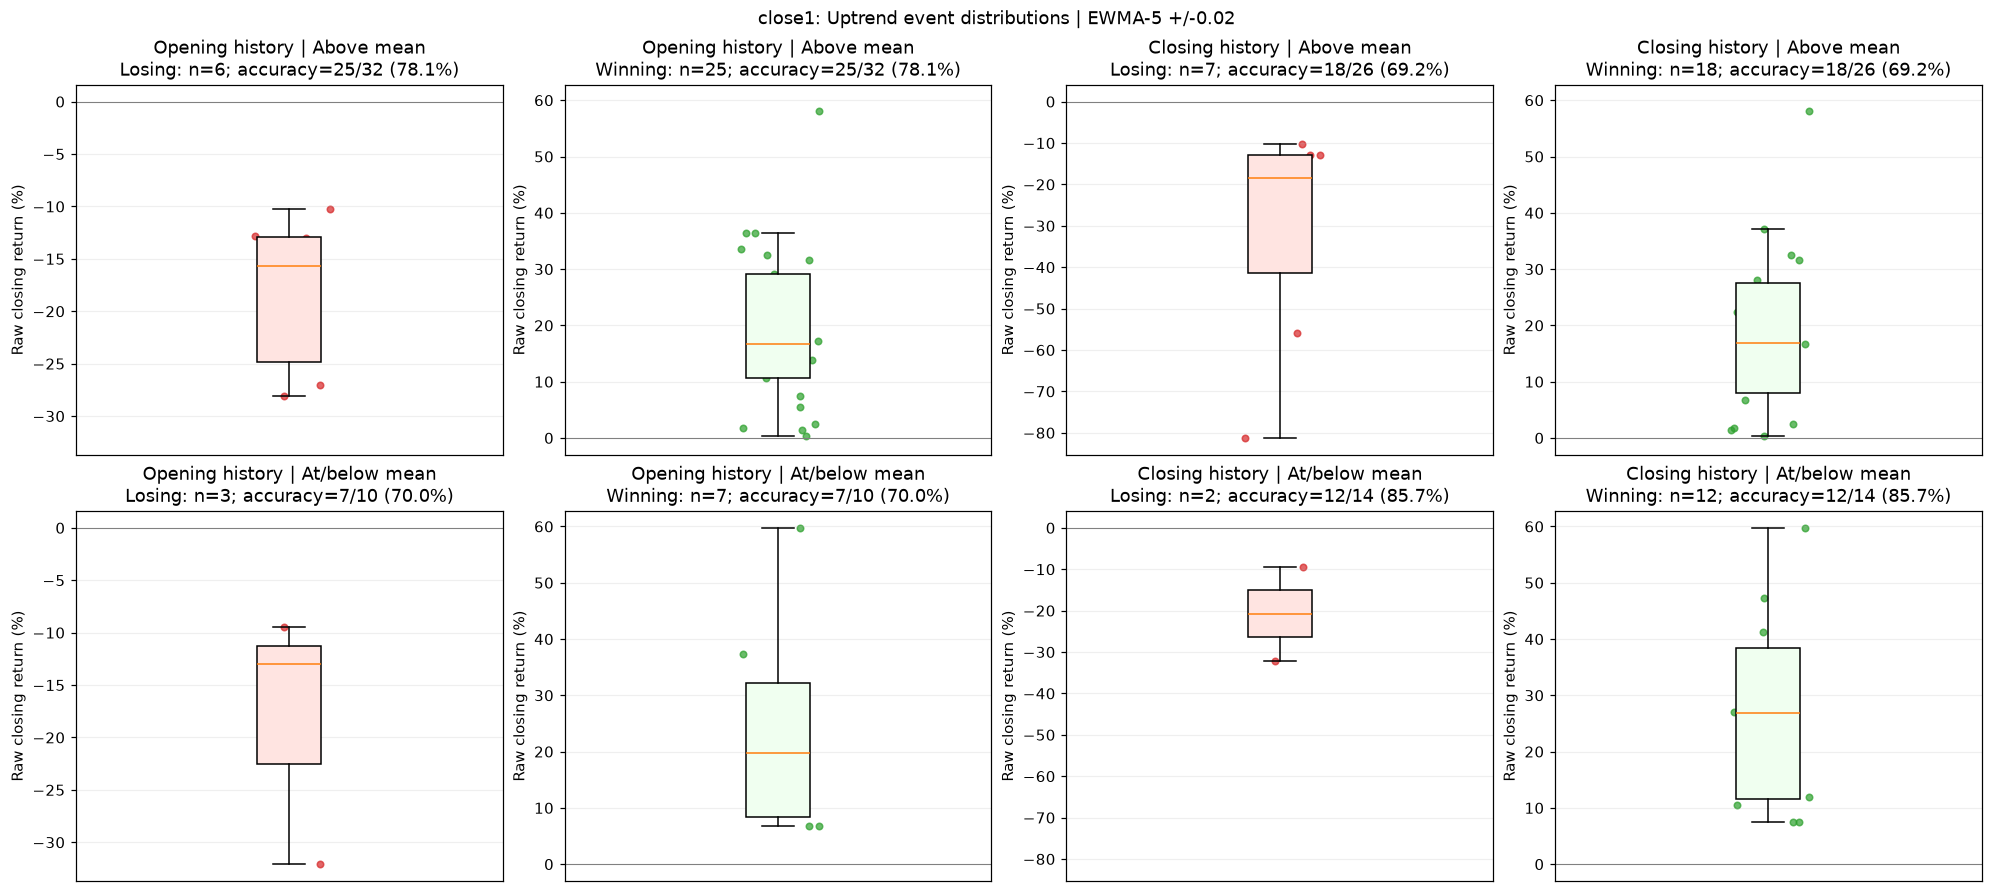

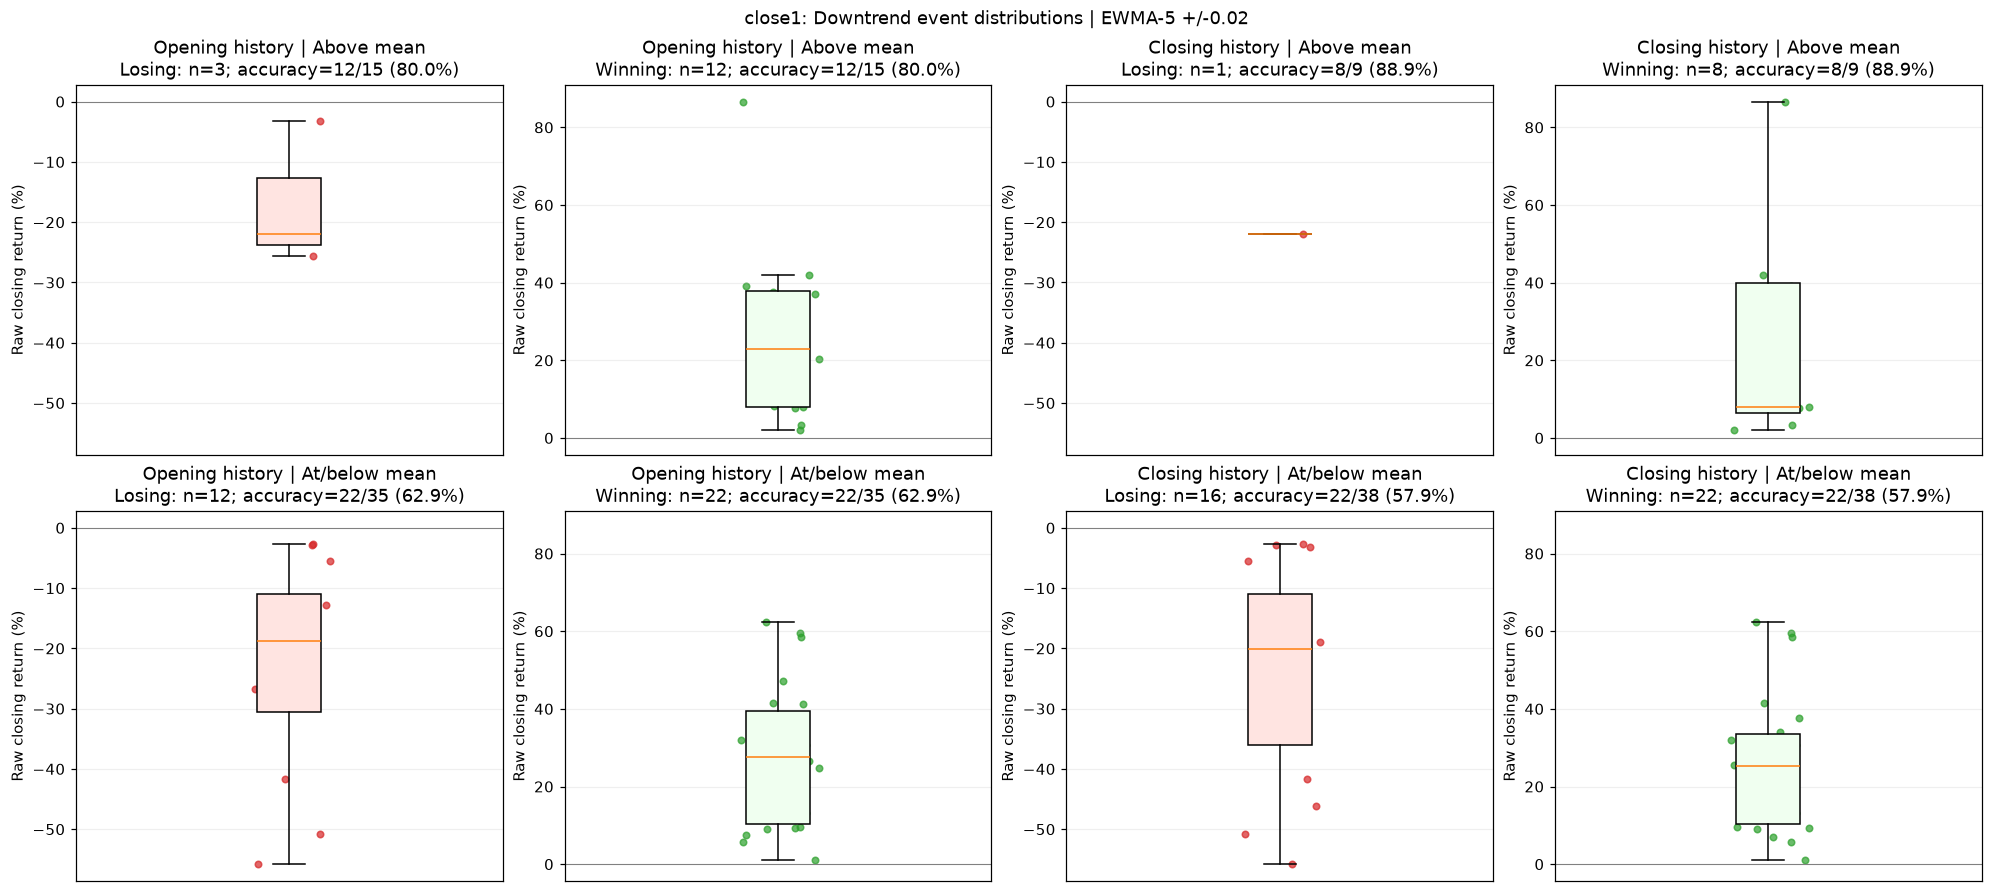

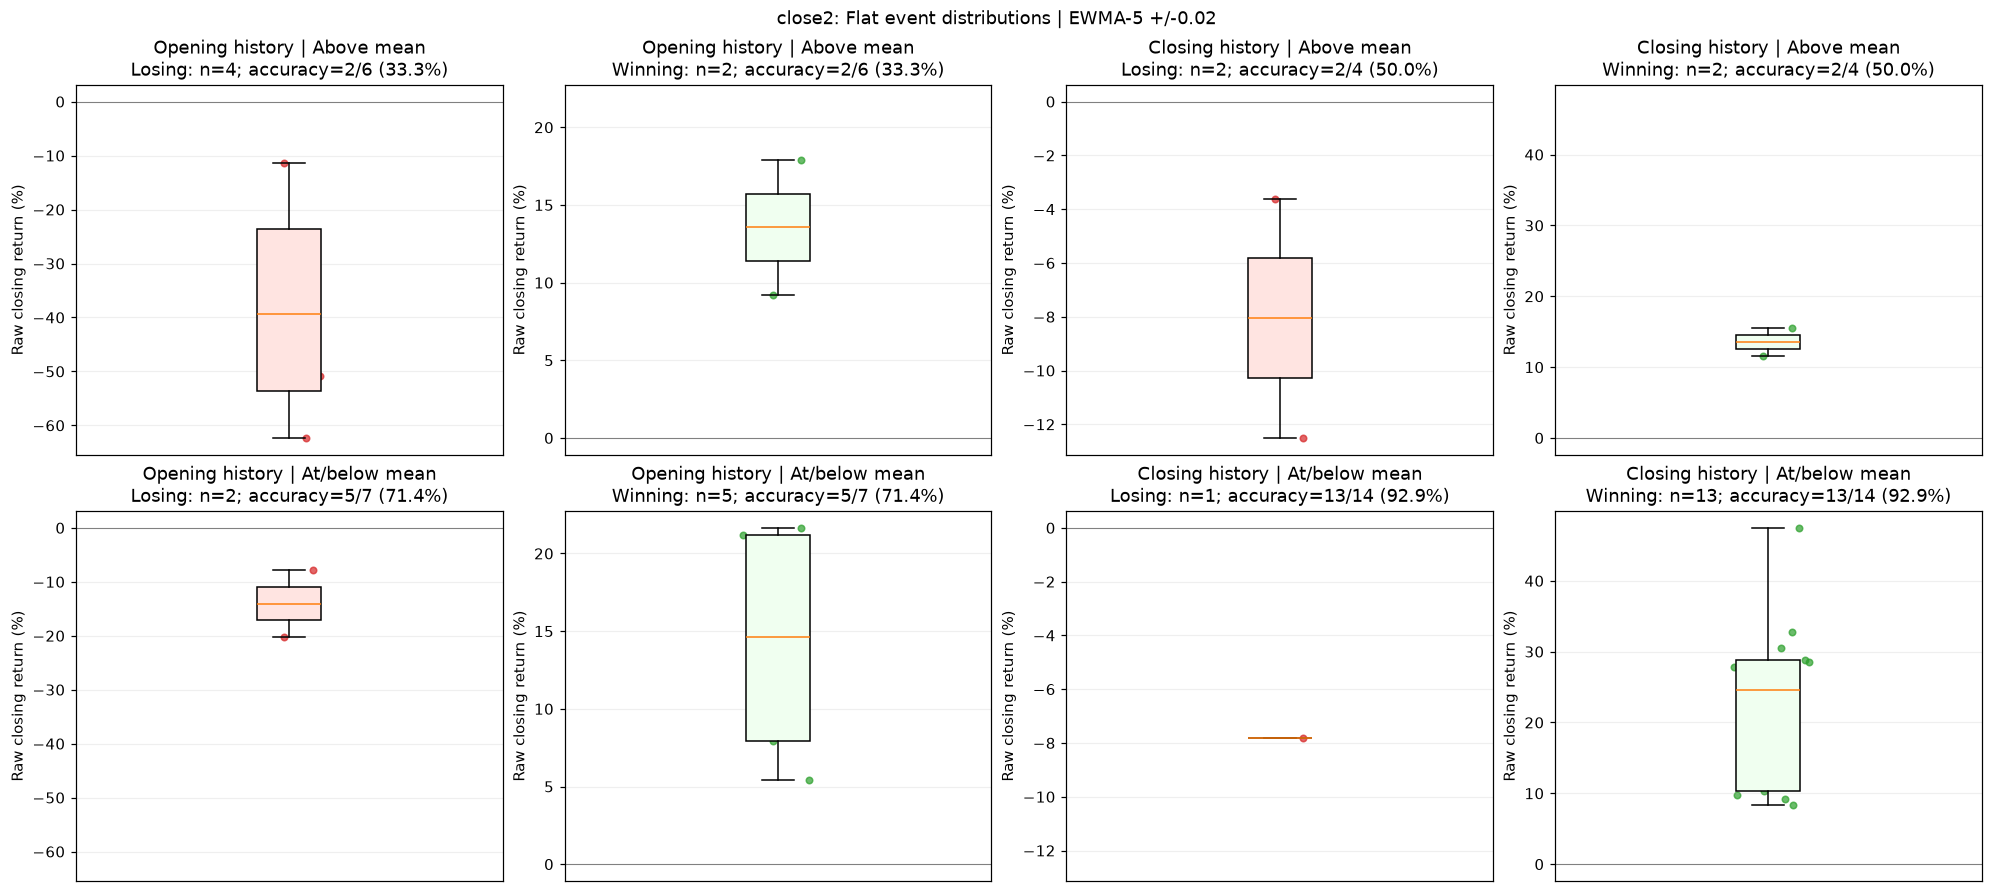

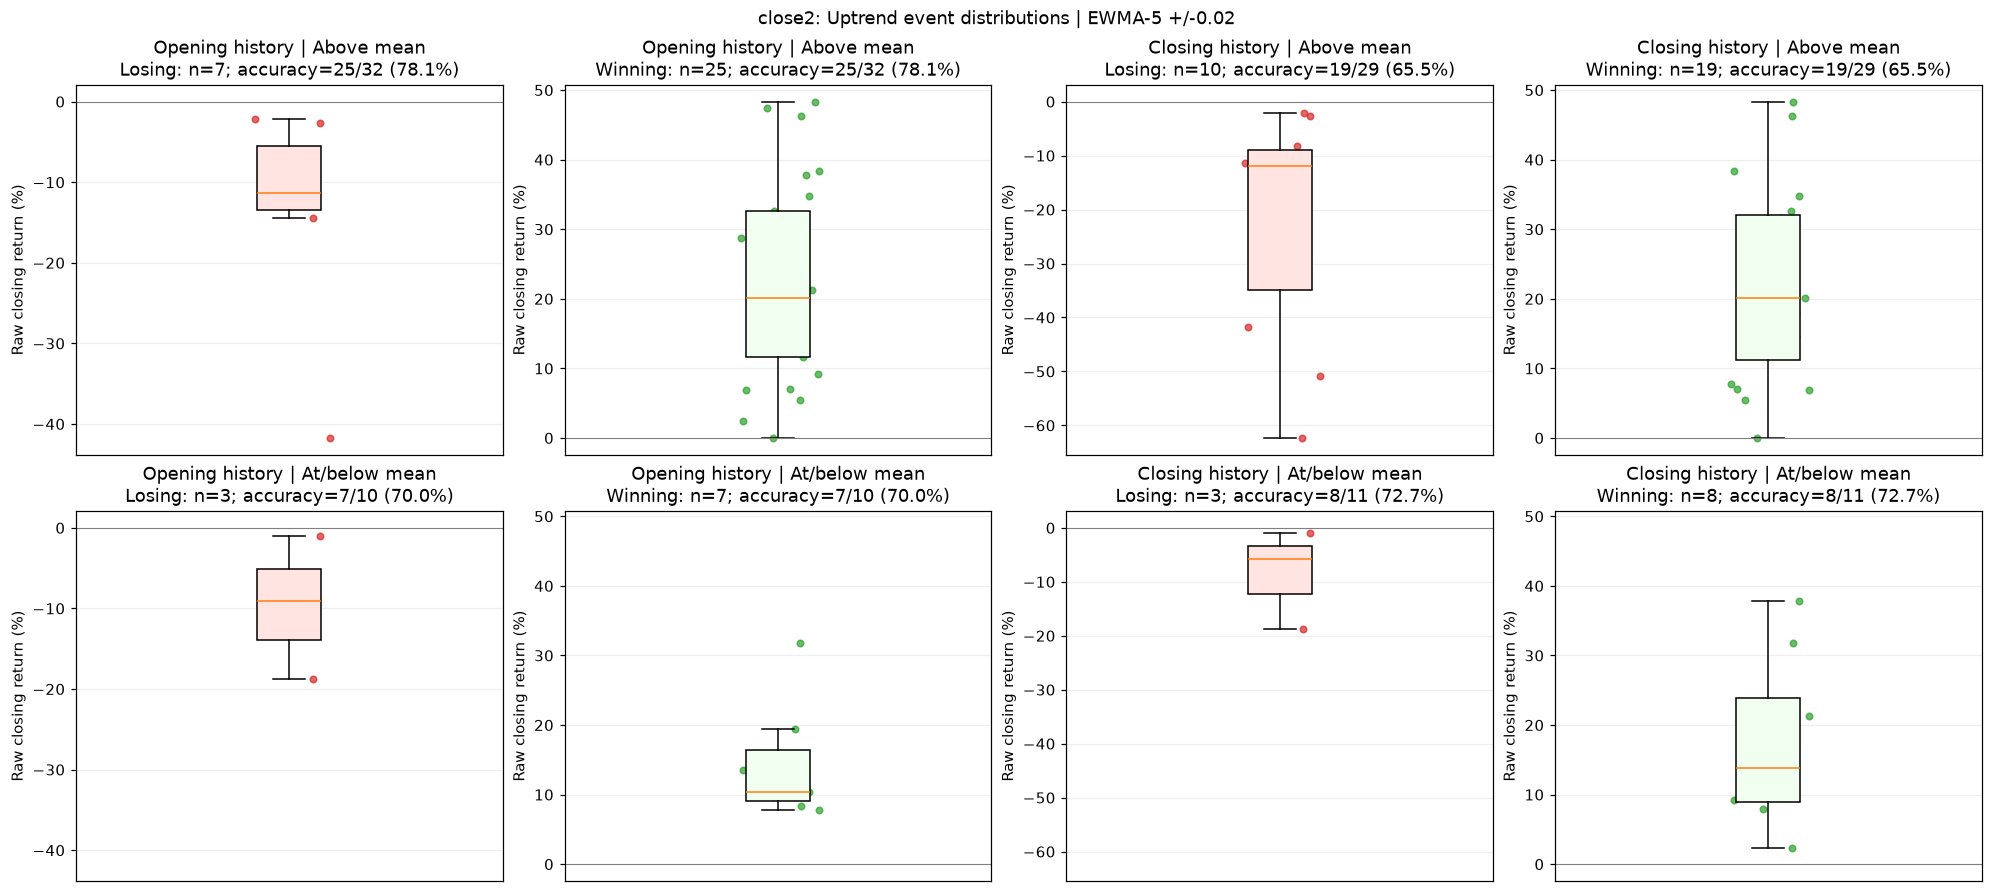

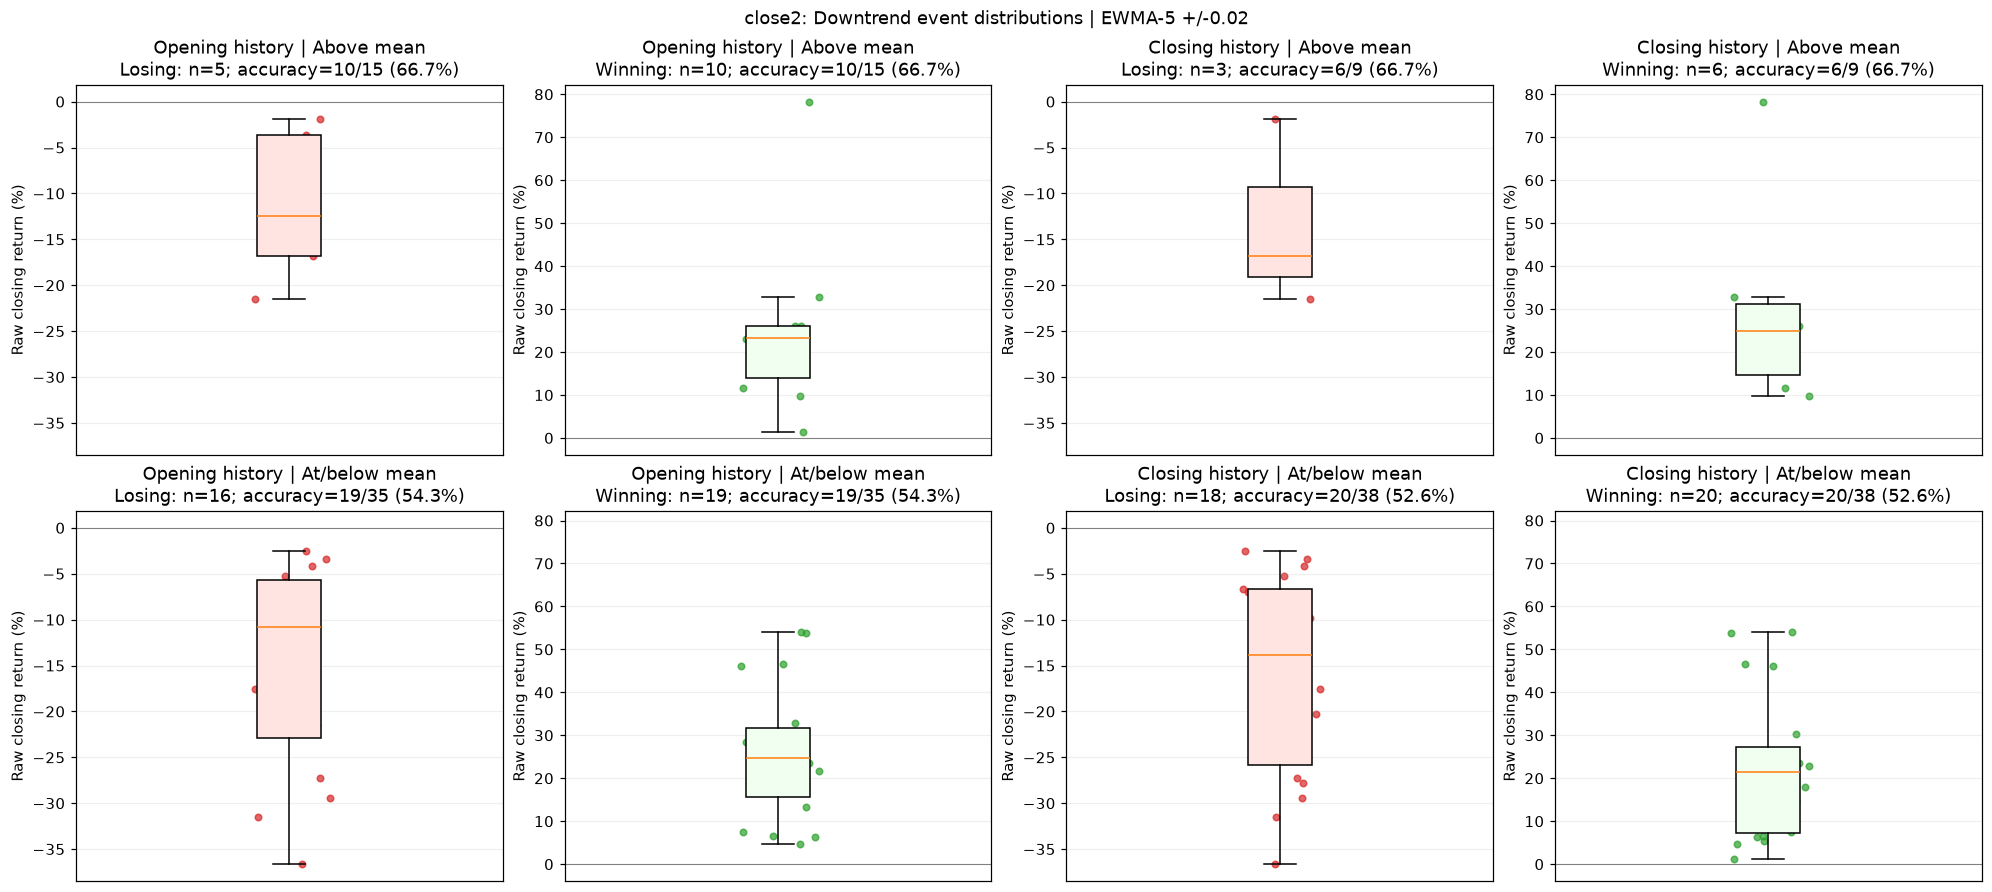

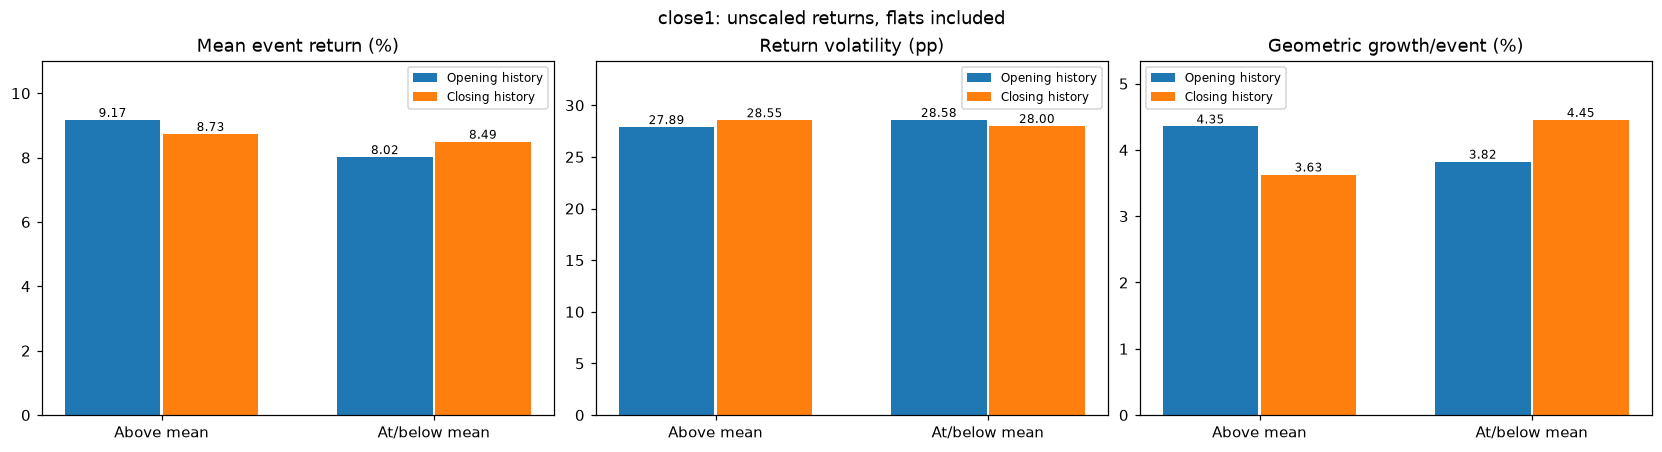

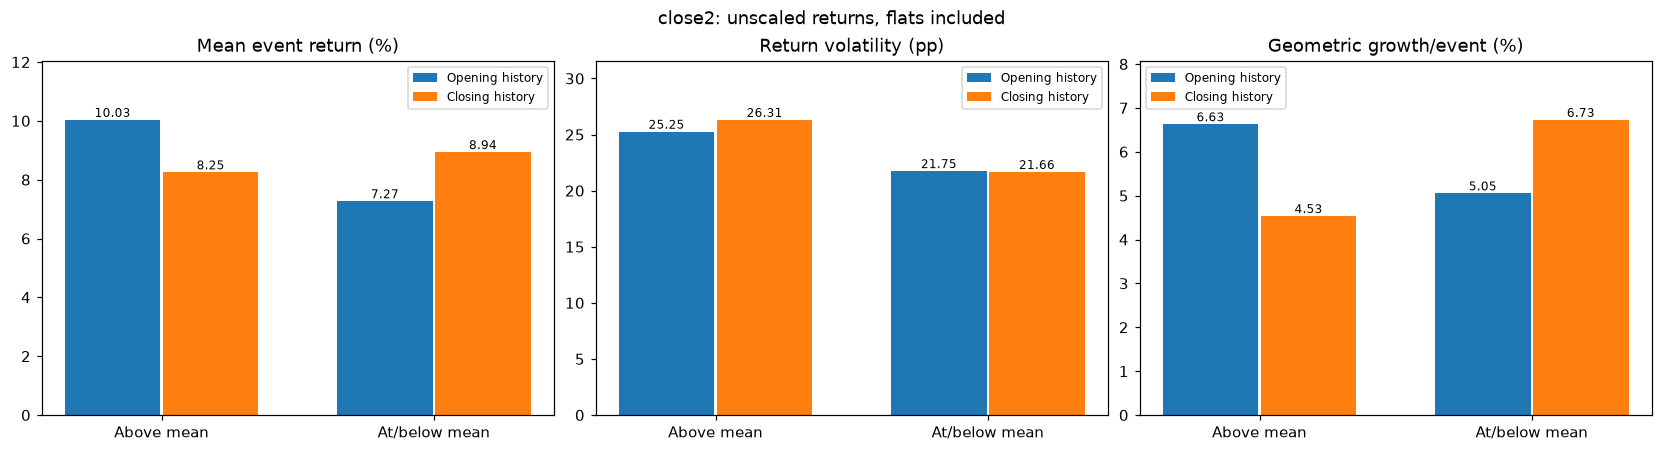

In [6]:
accuracy_rows=[];mean_rows=[]
for market in ['close1','close2']:
    for source in ['Opening history','Closing history']:
        result=comparison_results[(market,source,*DETAIL)]
        data=result['source']['events'][['regime','trend']].join(result['events'].return_pct)
        for regime,part in data.groupby('regime'):
            mean_rows.append(dict(market=market,history=source,regime=regime,**metrics(part.return_pct)))
    for trend in ['Flat','Uptrend','Downtrend']:
        fig,axes=plt.subplots(2,4,figsize=(18,8),sharey='col',constrained_layout=True)
        for source_idx,source in enumerate(['Opening history','Closing history']):
            result=comparison_results[(market,source,*DETAIL)]
            data=result['source']['events'][['regime','trend']].join(result['events'].return_pct)
            for row,regime in enumerate(['Above mean','At/below mean']):
                part=data.loc[data.regime.eq(regime)&data.trend.eq(trend)]
                wins=int(part.return_pct.gt(0).sum());count=len(part);accuracy=100*wins/count if count else np.nan
                accuracy_rows.append(dict(market=market,history=source,regime=regime,trend=trend,events=count,
                    wins=wins,losses=int(part.return_pct.lt(0).sum()),zeros=int(part.return_pct.eq(0).sum()),accuracy_pct=accuracy))
                for j,(outcome,mask) in enumerate([('Losing',part.return_pct.lt(0)),('Winning',part.return_pct.gt(0))]):
                    values=part.loc[mask,'return_pct'];ax=axes[row,source_idx*2+j]
                    if len(values):
                        boxes=ax.boxplot([values],patch_artist=True,showfliers=False)
                        boxes['boxes'][0].set_facecolor('mistyrose' if j==0 else 'honeydew')
                        ax.scatter(1+np.random.default_rng(42).uniform(-.1,.1,len(values)),values,s=18,alpha=.7,color='tab:red' if j==0 else 'tab:green')
                    else:ax.text(.5,.5,'No events',transform=ax.transAxes,ha='center')
                    ax.set(title=f'{source} | {regime}\n{outcome}: n={len(values)}; accuracy={wins}/{count} ({accuracy:.1f}%)',ylabel='Raw closing return (%)')
                    ax.set_xticks([]);ax.axhline(0,color='gray',lw=.7);ax.grid(axis='y',alpha=.2)
        fig.suptitle(f'{market}: {trend} event distributions | EWMA-5 +/-0.02');plt.show()
accuracy_summary=pd.DataFrame(accuracy_rows);mean_group_summary=pd.DataFrame(mean_rows)
assert accuracy_summary.groupby(['market','history']).events.sum().eq(105).all()
print(accuracy_summary.to_string(index=False))
for market in ['close1','close2']:
    fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
    for ax,col,title in zip(axes,['average_return_pct','volatility_pp','geometric_growth_pct'],['Mean event return (%)','Return volatility (pp)','Geometric growth/event (%)']):
        for offset,source in [(-.18,'Opening history'),(.18,'Closing history')]:
            values=mean_group_summary.loc[(mean_group_summary.market==market)&(mean_group_summary.history==source)].set_index('regime').reindex(['Above mean','At/below mean'])[col]
            bars=ax.bar(np.arange(2)+offset,values,.35,label=source);ax.bar_label(bars,fmt='%.2f',fontsize=8)
        ax.set_xticks([0,1],['Above mean','At/below mean']);ax.set_title(title);ax.legend(fontsize=8);ax.margins(y=.2)
    fig.suptitle(f'{market}: unscaled returns, flats included');plt.show()


## Rolling Brier history

For each closing market, compare opening and closing advantage histories. Panel 1 uses event-end 100-fight averages over train, validation, and test; model refit is marked. Panels 2–3 use train+validation fitted predictions, the source notebook's fight ordering, and 100-fight averages of actual/expected and excess Brier. Opening is included for comparison.

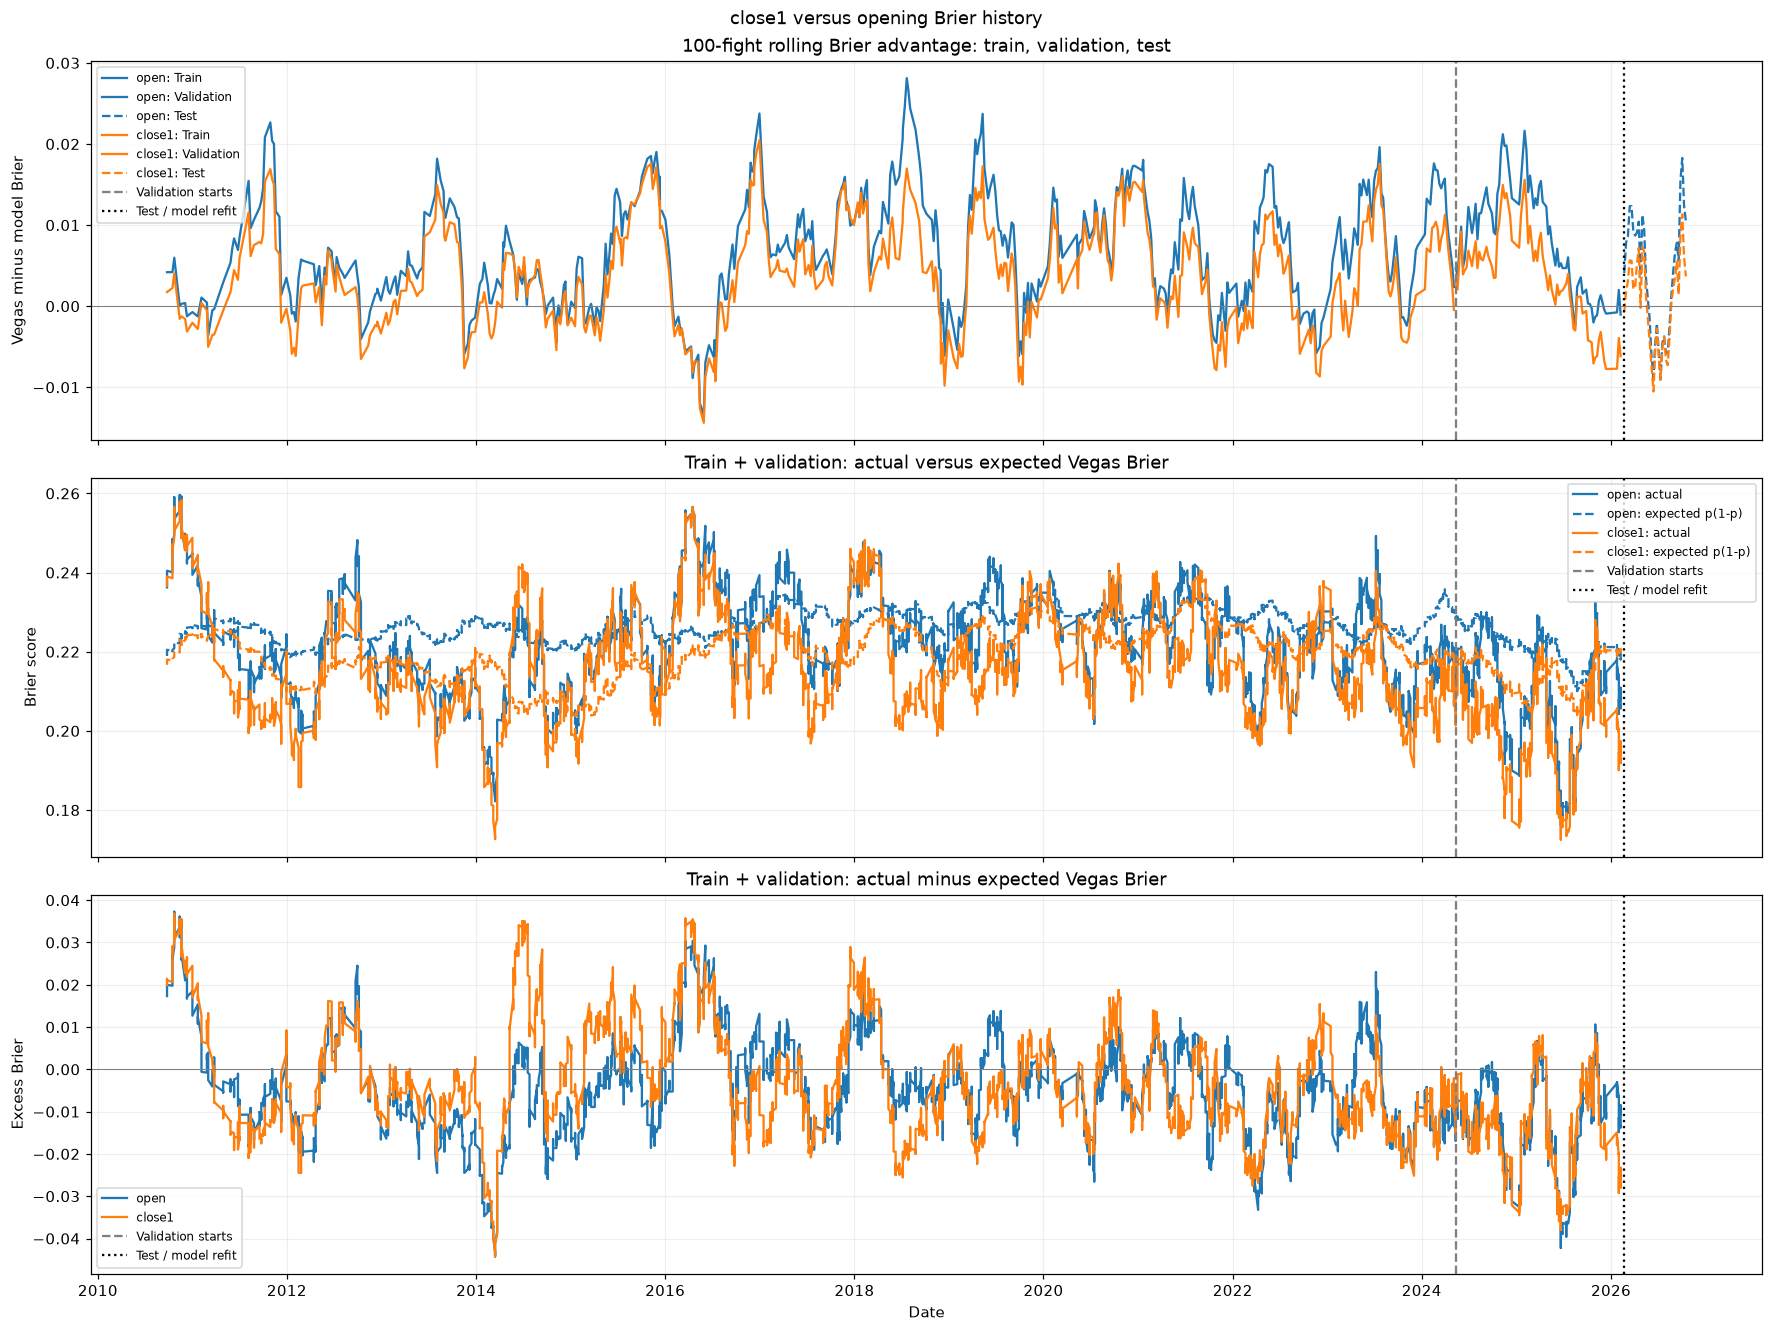

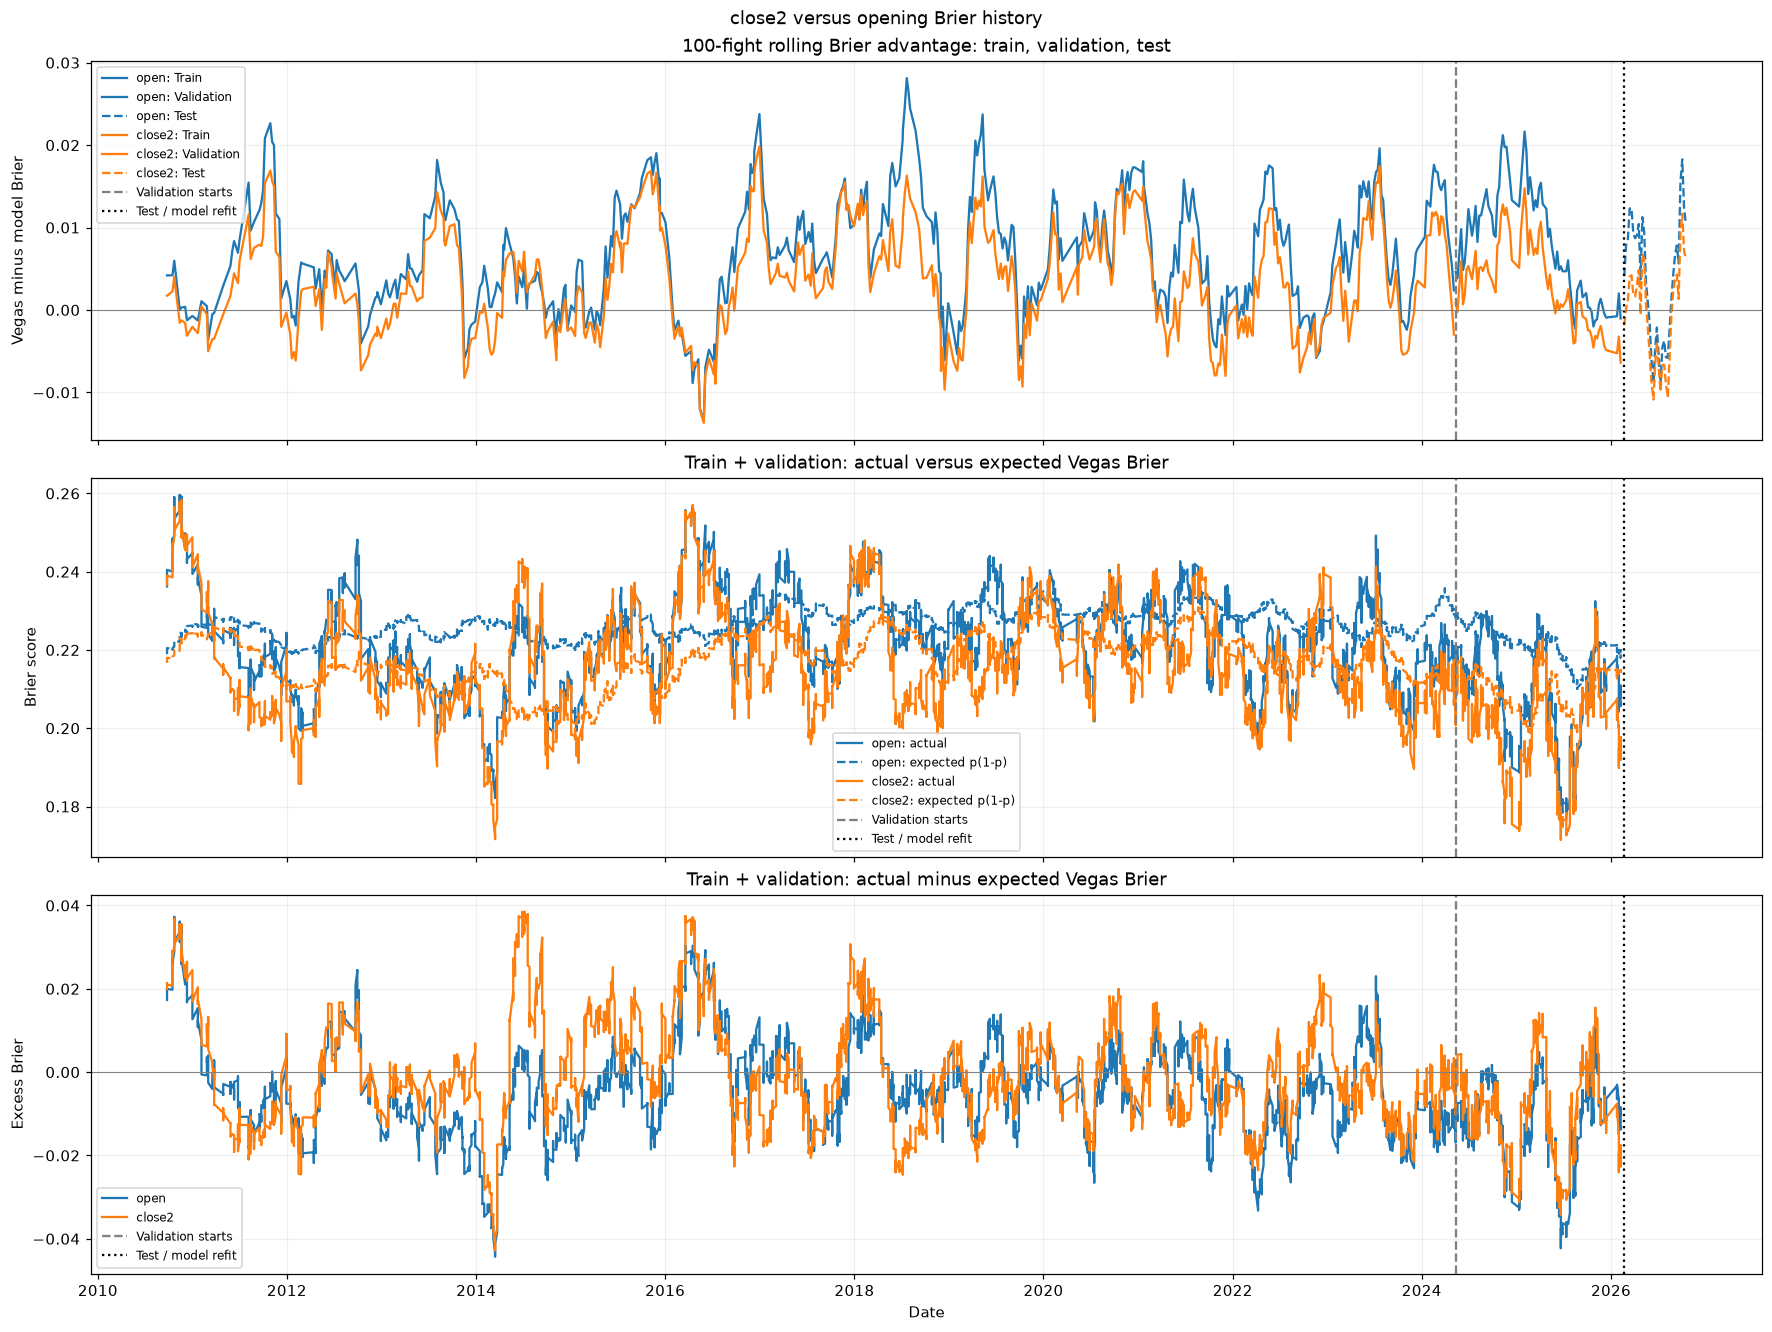

In [7]:
import matplotlib.dates as mdates
train_end=pd.to_datetime(pd.read_csv(PREDICTIONS/'train/open/inference/train_with_open.csv').date).max()
for market in ['close1','close2']:
    fig,axes=plt.subplots(3,1,figsize=(16,12),sharex=True,constrained_layout=True)
    for source,color in [('open','tab:blue'),(market,'tab:orange')]:
        result=source_results[(source,*DETAIL)]
        for stage,style in [('Train','-'),('Validation','-'),('Test','--')]:
            history=result['histories']['Test' if stage=='Test' else 'Validation']
            ends=history.groupby('date').rolling_advantage.last()
            points=ends.loc[ends.index<=train_end] if stage=='Train' else ends.reindex(result['events'].index[result['events'].split.eq(stage)])
            axes[0].plot(points.index,points,color=color,ls=style,label=f'{source}: {stage}')
        history=pd.read_csv(PREDICTIONS/f'trainval/open/inference/train_with_{source}.csv')
        history['date']=pd.to_datetime(history.date)
        order=['date']+(['bout_position'] if 'bout_position' in history else [])+['fighter_red','fighter_blue']
        history=score_fights(history.sort_values(order,kind='stable'),source)
        for measure in ['vegas_actual','vegas_expected','excess']:
            history['rolling_'+measure]=history[measure].rolling(100,min_periods=100).mean()
        axes[1].plot(history.date,history.rolling_vegas_actual,color=color,label=f'{source}: actual')
        axes[1].plot(history.date,history.rolling_vegas_expected,color=color,ls='--',label=f'{source}: expected p(1-p)')
        axes[2].plot(history.date,history.rolling_excess,color=color,label=source)
    dates=source_results[(market,*DETAIL)]['events']
    for ax in axes:
        ax.axvline(dates.index[dates.split.eq('Validation')].min(),color='gray',ls='--',label='Validation starts')
        ax.axvline(dates.index[dates.split.eq('Test')].min(),color='black',ls=':',label='Test / model refit')
        ax.legend(fontsize=8);ax.grid(alpha=.2)
    axes[0].set(title='100-fight rolling Brier advantage: train, validation, test',ylabel='Vegas minus model Brier');axes[0].axhline(0,color='gray',lw=.7)
    axes[1].set(title='Train + validation: actual versus expected Vegas Brier',ylabel='Brier score')
    axes[2].set(title='Train + validation: actual minus expected Vegas Brier',ylabel='Excess Brier',xlabel='Date');axes[2].axhline(0,color='gray',lw=.7)
    fig.suptitle(f'{market} versus opening Brier history');plt.show()


## Event-only Brier correlations with closing returns

Same 72 validation return observations, including flat events. Compare features from opening and closing history against identical closing returns. Window 0 means the previous event's average. Same-event advantage shares outcomes with returns. Pearson intervals are approximate 95% paired moving-block bootstrap intervals (2,000 samples, 5-event blocks, seed 42).

market history                            feature  n       r  ci_low  ci_high  spearman
close1    open Prior actual Vegas Brier (0-fight) 72  0.0788 -0.1372   0.2915    0.0321
close1    open              Prior-event advantage 72 -0.0190 -0.2078   0.1742   -0.0542
close1    open               Same-event advantage 72  0.5926  0.3142   0.7335    0.5301
close1  close1 Prior actual Vegas Brier (0-fight) 72  0.1276 -0.1126   0.4016    0.0963
close1  close1              Prior-event advantage 72  0.0332 -0.1765   0.2697   -0.0105
close1  close1               Same-event advantage 72  0.5418  0.2809   0.6667    0.5250
close2    open Prior actual Vegas Brier (0-fight) 72  0.1554 -0.0456   0.3506    0.1318
close2    open              Prior-event advantage 72 -0.0619 -0.2546   0.1255   -0.1129
close2    open               Same-event advantage 72  0.5992  0.4291   0.7051    0.5646
close2  close2 Prior actual Vegas Brier (0-fight) 72  0.2346 -0.0001   0.4834    0.2057
close2  close2              Prio

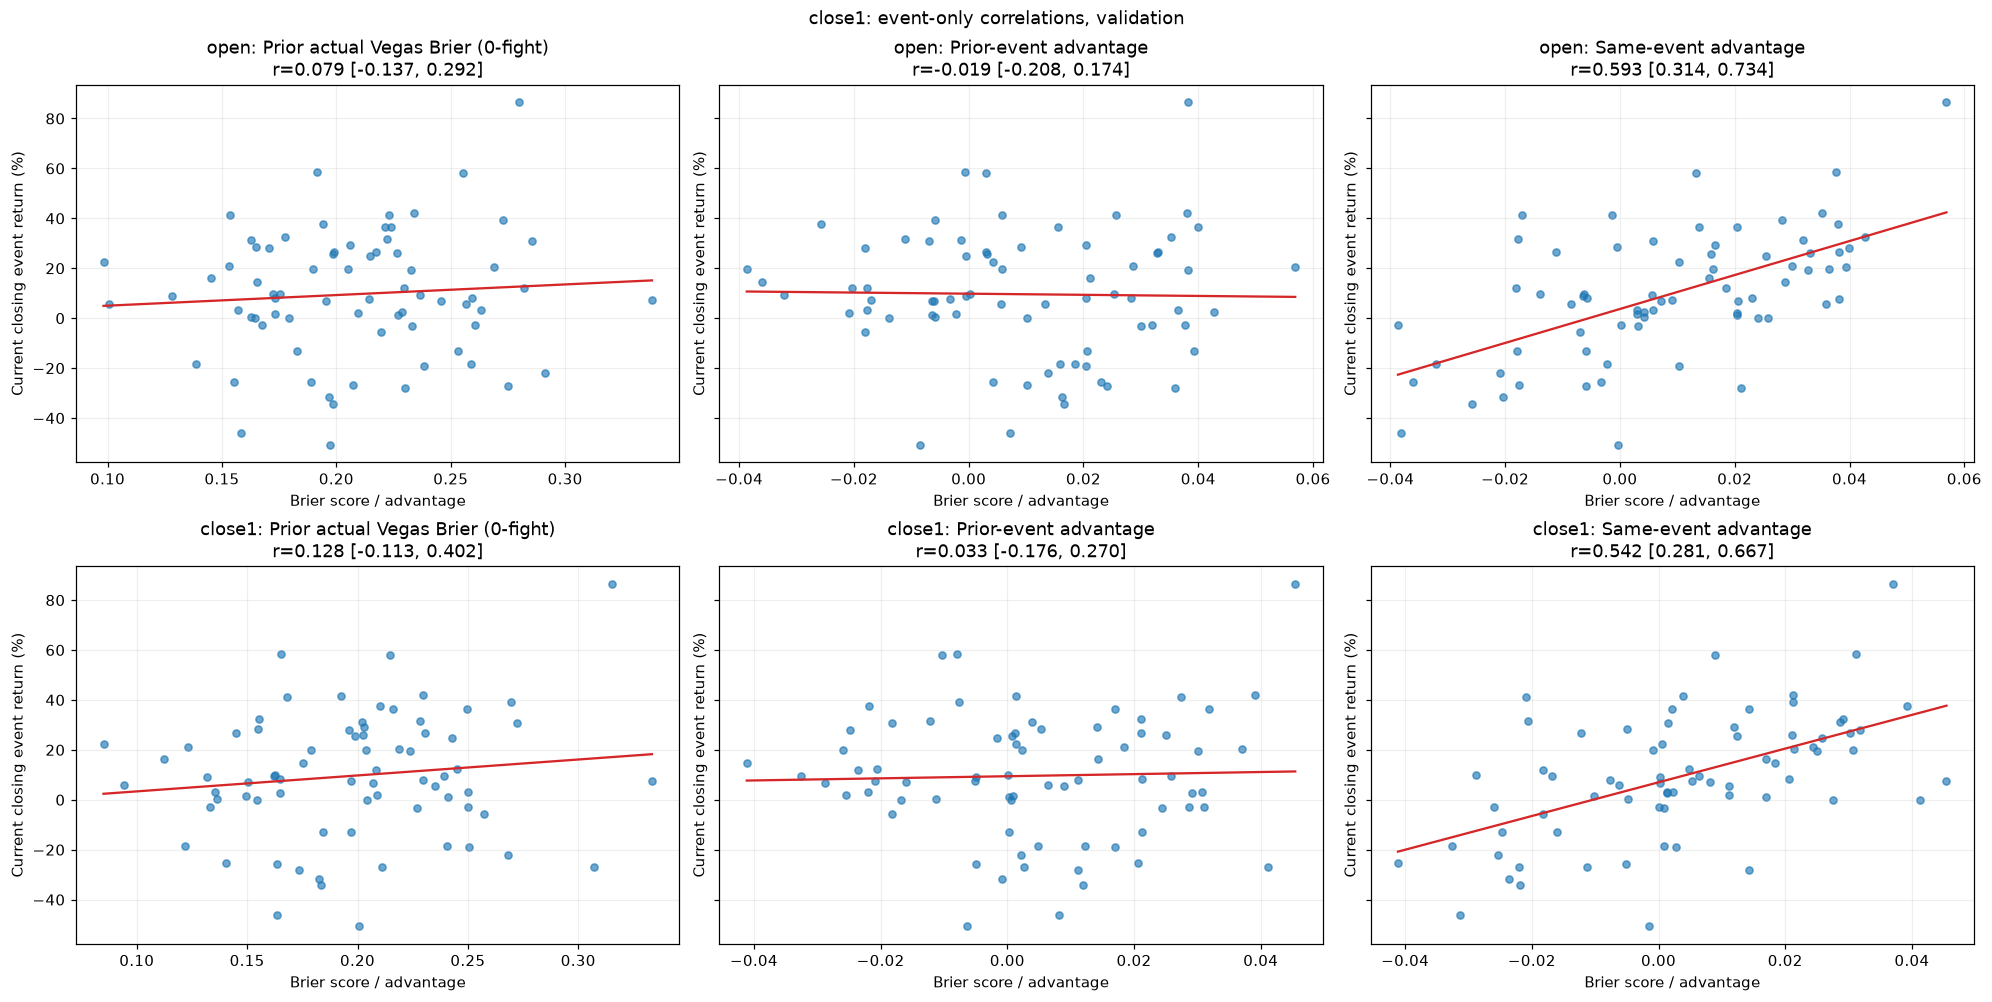

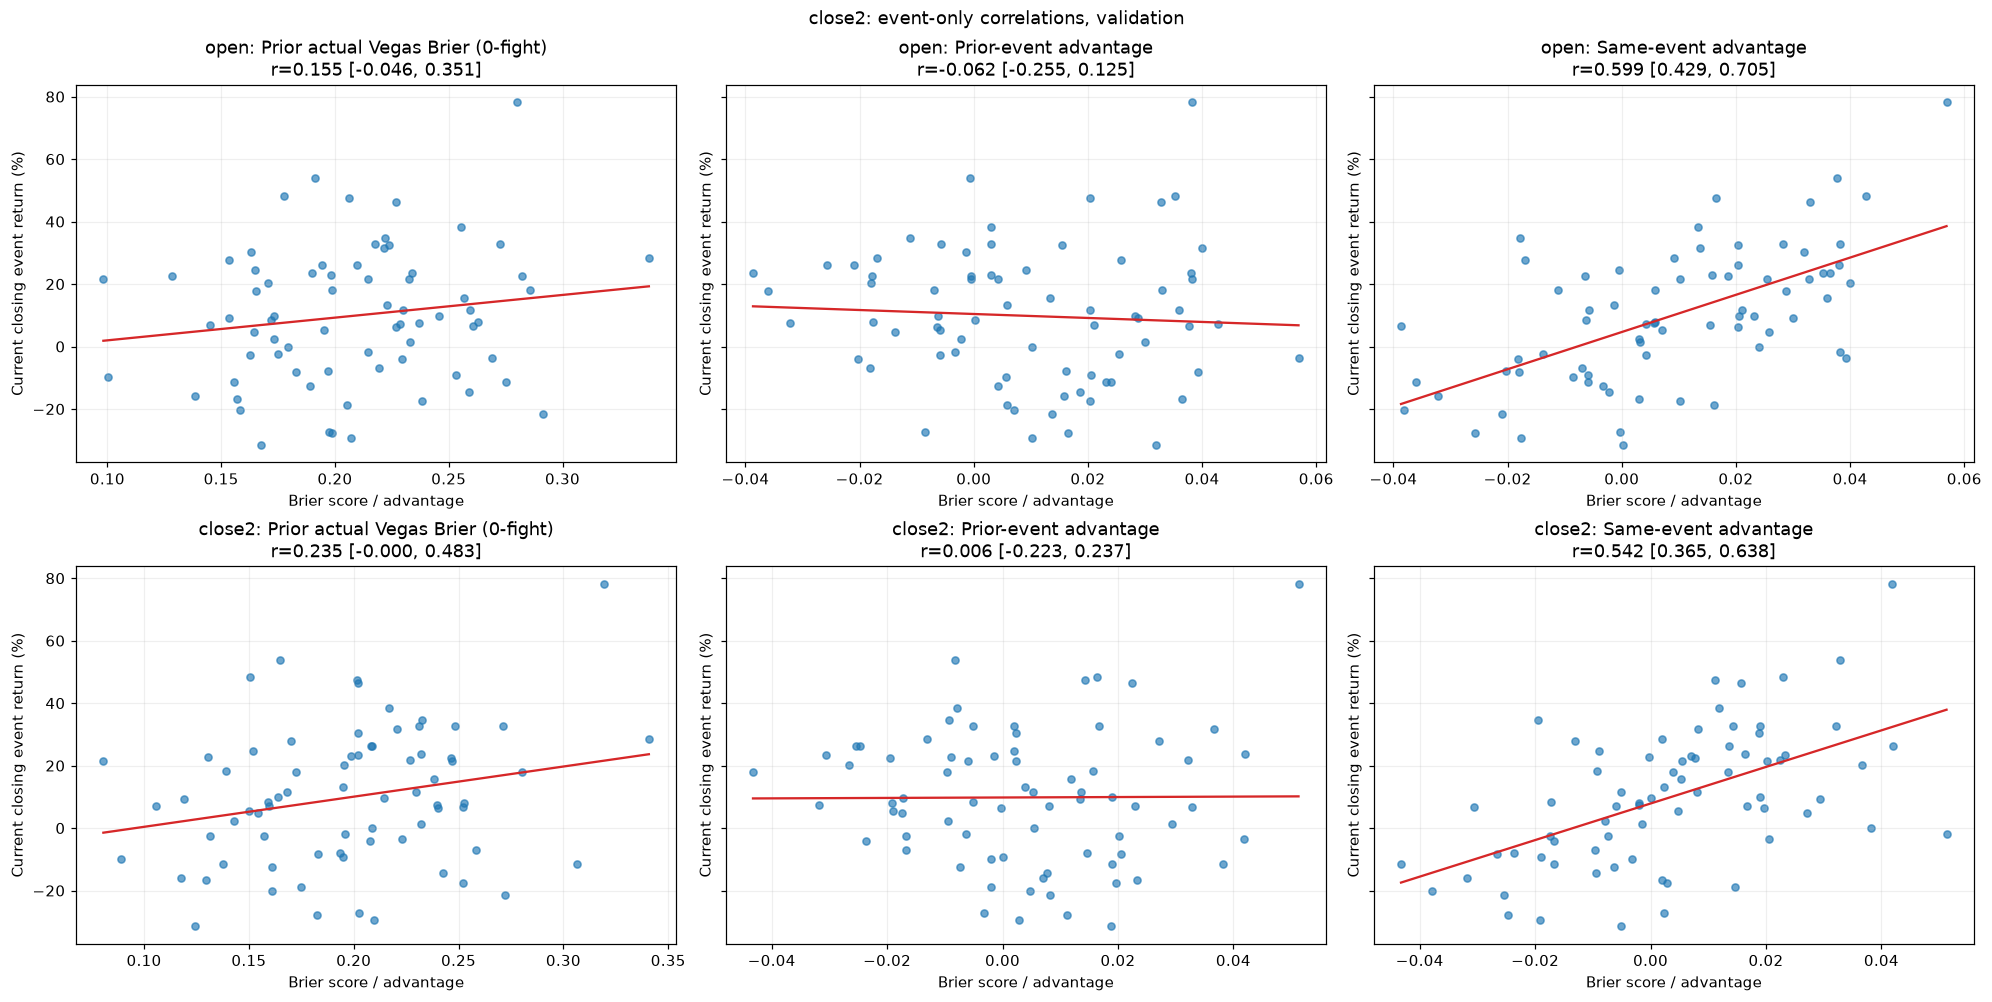

In [8]:
from scipy.stats import pearsonr, spearmanr
def event_only_pearson_ci(x,y):
    rng=np.random.default_rng(42)
    x=np.asarray(x,float);y=np.asarray(y,float)
    count=len(x);block=min(5,count);draws=2000
    starts=rng.integers(0,count-block+1,size=(draws,int(np.ceil(count/block))))
    ids=(starts[:,:,None]+np.arange(block)).reshape(draws,-1)[:,:count]
    a=x[ids];b=y[ids]
    a-=a.mean(axis=1,keepdims=True);b-=b.mean(axis=1,keepdims=True)
    denominator=np.sqrt((a*a).sum(axis=1)*(b*b).sum(axis=1))
    cor=np.divide((a*b).sum(axis=1),denominator,out=np.full(draws,np.nan),where=denominator>0)
    return np.quantile(cor[np.isfinite(cor)],[.025,.975])


correlation_rows=[]
for market in ['close1','close2']:
    target=source_results[(market,*DETAIL)]['events'];returns=target.loc[target.split.eq('Validation'),'return_pct']
    fig,axes=plt.subplots(2,3,figsize=(18,9),sharey=True,constrained_layout=True)
    for row,source in enumerate(['open',market]):
        history=source_results[(source,*DETAIL)]['histories']['Validation']
        scores=history.groupby('date')[['vegas_actual','advantage']].mean()
        specs=[('Prior actual Vegas Brier (0-fight)',scores.vegas_actual.shift(1)),
               ('Prior-event advantage',scores.advantage.shift(1)),('Same-event advantage',scores.advantage)]
        for ax,(label,values) in zip(axes[row],specs):
            sample=pd.DataFrame({'x':values.reindex(returns.index),'y':returns}).dropna();assert len(sample)==72
            r=pearsonr(sample.x,sample.y).statistic;rho=spearmanr(sample.x,sample.y).statistic
            lo,hi=event_only_pearson_ci(sample.x,sample.y)
            correlation_rows.append(dict(market=market,history=source,feature=label,n=len(sample),r=r,ci_low=lo,ci_high=hi,spearman=rho))
            ax.scatter(sample.x,sample.y,s=22,alpha=.65)
            grid=np.linspace(sample.x.min(),sample.x.max(),100);ax.plot(grid,np.polyval(np.polyfit(sample.x,sample.y,1),grid),color='tab:red')
            ax.set(title=f'{source}: {label}\nr={r:.3f} [{lo:.3f}, {hi:.3f}]',xlabel='Brier score / advantage',ylabel='Current closing event return (%)');ax.grid(alpha=.2)
    fig.suptitle(f'{market}: event-only correlations, validation');plt.show()
correlation_summary=pd.DataFrame(correlation_rows)
print(correlation_summary.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
